# 1. Подготовка данных

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, average_precision_score,
                             brier_score_loss, confusion_matrix)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
plt.rcParams.update({'figure.figsize': (14, 4), 'axes.grid': True, 'grid.alpha': 0.25})
pd.set_option('display.max_columns', None)

data_path = Path('../data') / 'deals_all_opt_2026-09-11__risk_uniform.csv'
validation_start = pd.Timestamp('2024-01-01')
test_start = pd.Timestamp('2025-01-01')
windows = [1, 3, 5, 7, 14]
probability_grid = np.arange(0.30, 0.71, 0.05).round(2)

In [3]:
trades = pd.read_csv(data_path, parse_dates=['entry_date', 'exit_date'])
trades = trades.sort_values(['entry_date', 'exit_date']).reset_index(drop=True)
trades['entry_day'] = trades.entry_date.dt.normalize()
trades['exit_day'] = trades.exit_date.dt.normalize()
cash_initial = float(trades.start_equity.iloc[0])
test_end = trades.exit_day.max()
calendar = pd.date_range(trades.entry_day.min(), test_end, name='Date')

events = trades.groupby('exit_date').profit_abs.sum().sort_index()
equity = cash_initial + events.cumsum()
drawdown = ((equity / equity.cummax().clip(lower=cash_initial) - 1) * 100).clip(upper=0)
underwater = drawdown.lt(-1e-10)
episode_id = (~underwater).cumsum()
episode_start = drawdown.index.to_series().where(underwater & ~underwater.shift(fill_value=False))
episode_start = episode_start.ffill().where(underwater)

last_close = events.index.searchsorted(calendar, side='left') - 1

def at_day_start(series):
    values = series.reindex(events.index).to_numpy()
    return pd.Series(values[np.maximum(last_close, 0)], index=calendar).where(last_close >= 0)

daily = trades.assign(win=trades.profit_abs.gt(0)).groupby('exit_day').agg(
    pnl=('profit_abs', 'sum'), wins=('win', 'sum'), closes=('win', 'size')
).reindex(calendar, fill_value=0)
daily_balance = cash_initial + daily.pnl.cumsum()
opening_balance = daily_balance.shift(1, fill_value=cash_initial)
known_start = at_day_start(episode_start)
features = pd.DataFrame({
    'drawdown_pct': at_day_start(drawdown).fillna(0),
    'days_underwater': (calendar.to_series() - known_start).dt.total_seconds().div(86400).fillna(0),
})
for days in windows:
    closes = daily.closes.rolling(days).sum().shift(1)
    wins = daily.wins.rolling(days).sum().shift(1)
    features[f'closes_{days}d'] = closes
    features[f'winrate_{days}d'] = wins / closes.where(closes.gt(0))
    features[f'return_{days}d'] = (opening_balance / opening_balance.shift(days) - 1) * 100

features = features.iloc[max(windows):]

# 2. Разметка данных

Метка `1` — от начала снижения до первого дна включительно, если дно глубже заданной границы. Остальные известные состояния — `0`. Эпизоды, пересекающие границы выборок, не размечаем для следующего отрезка; незавершённые эпизоды исключаем из обучения и валидации. На тесте у незавершённого эпизода метка `1` допустима только до наблюдаемого дна, если порог уже пробит; неопределённый остаток исключаем из ML-метрик.

### Способ 1: дно глубже −3,5%

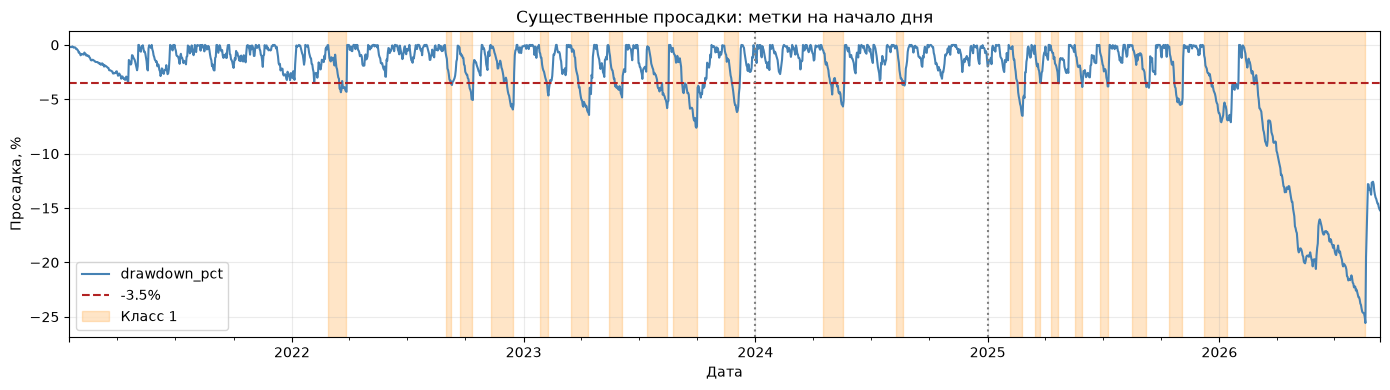

In [4]:
def label_episodes(start, stop, depth_threshold, include_open=False):
    history = drawdown.loc[drawdown.index < stop]
    dd_mask = underwater.reindex(history.index)
    labels = pd.Series(0.0, index=history.index)

    for _, episode in history[dd_mask].groupby(episode_id):
        begin = episode.index[0]
        is_open = episode.index[-1] == history.index[-1]
        trough = episode.idxmin()
        if begin < start or is_open:
            labels.loc[episode.index] = np.nan
        if begin >= start and episode.min() < depth_threshold and (not is_open or include_open):
            labels.loc[episode.loc[:trough].index] = 1

    return at_day_start(labels).loc[(calendar >= start) & (calendar < stop)]

train_start = features.index[0]
test_stop = test_end + pd.Timedelta(days=1)

def prepare_labels(depth_threshold):
    train = label_episodes(train_start, validation_start, depth_threshold)
    validation = label_episodes(validation_start, test_start, depth_threshold)
    test = label_episodes(test_start, test_stop, depth_threshold, include_open=True)
    y_train, y_validation, y_test = (y.dropna().astype(int) for y in (train, validation, test))
    fig, ax = plt.subplots()
    label_view = pd.concat([y_train, y_validation, y_test]).reindex(features.index)
    features.drawdown_pct.plot(ax=ax, color='steelblue')
    ax.axhline(depth_threshold, color='firebrick', linestyle='--', label=f'{depth_threshold:g}%')
    ax.fill_between(label_view.index, 0, 1, where=label_view.eq(1),
                    transform=ax.get_xaxis_transform(), step='post', color='darkorange',
                    alpha=0.22, label='Класс 1')
    for boundary in [validation_start, test_start]:
        ax.axvline(boundary, color='gray', linestyle=':')
    ax.set(title='Существенные просадки: метки на начало дня', ylabel='Просадка, %', xlabel='Дата')
    ax.legend(loc='lower left')
    plt.tight_layout()
    plt.show()
    return y_train, y_validation, y_test

labels_1 = prepare_labels(-3.5)

### Способ 2: дно глубже −2%

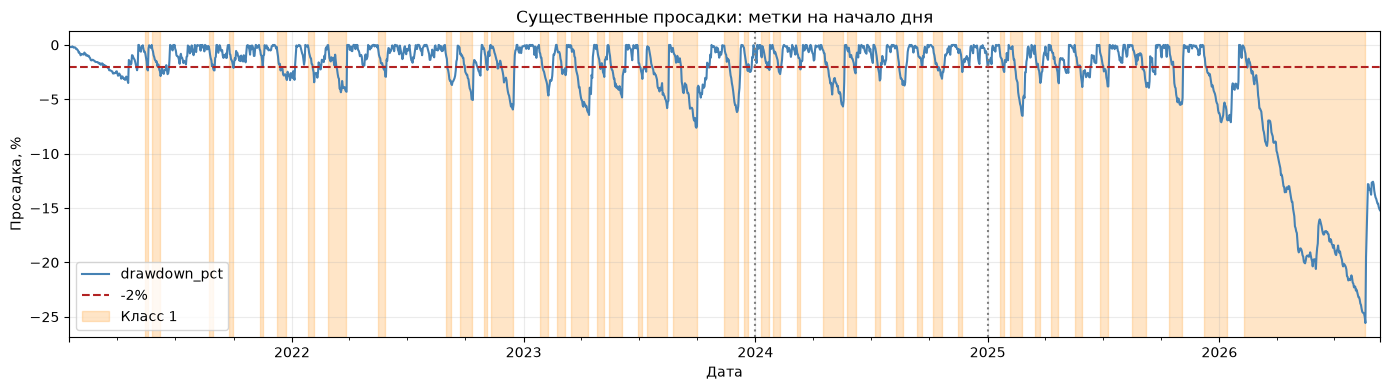

In [5]:
labels_2 = prepare_labels(-2.0)

### Способ 3: дно глубже −5%

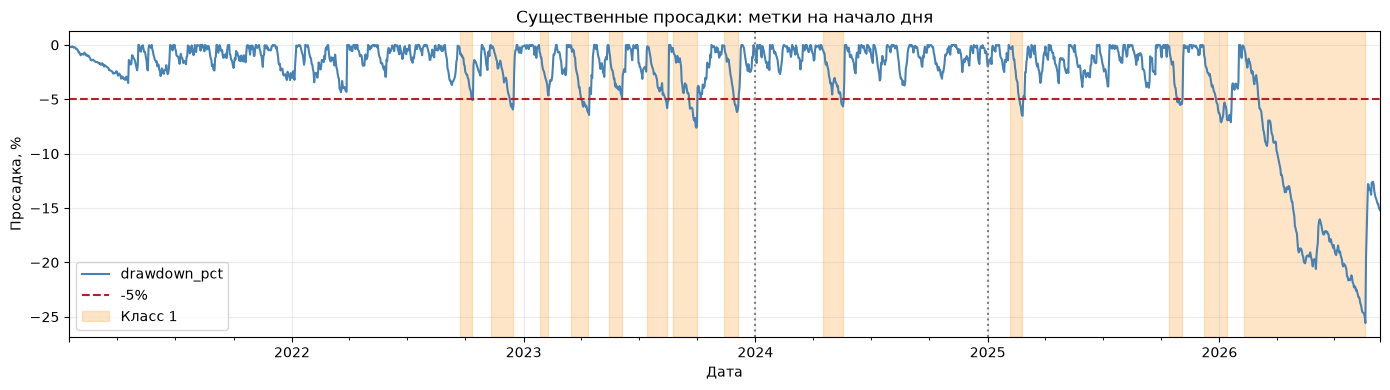

In [6]:
labels_3 = prepare_labels(-5.0)

# 3. Моделирование

Логистическая регрессия с L2 (`C=1`), заполнение пропусков медианой и стандартизация. Обучение: 2021–2023; подбор порога и множителя управления по Calmar: 2024; проверка: 2025–2026 YTD. Модель и признаки после валидации не меняем.

Для ML выбираем лучшую по Calmar настройку из всей сетки: ×0, ×0,5 или ×0,75. При ×0 новые входы временно пропускаются; при сигнале ниже порога они снова открываются полным объёмом. Уже открытые позиции не меняются.

На тесте сравниваем три способа: Baseline, управление по сигналу МЛ и Joint MDD 0/0 из гипотезы 5. Для Joint MDD пороги фиксируем по истории до 2025 года отдельно для каждой стратегии и для портфеля. Новый вход пропускается, если сработало хотя бы одно ограничение; каждый уровень возобновляет входы после восстановления своей виртуальной просадки до глубины меньше половины порога. Уже открытые позиции не меняются.

Метрики управления и классификации на тесте выводим отдельно за 2025 и 2026 (по последнюю дату данных). Графики общие за весь тест. Управление и открытые позиции переходят между годами без сброса; доходность, MDD и длительность просадок в годовых таблицах считаются внутри года от его начального капитала. Метки теста лишь разделяются по годам. При отрицательном PnL Baseline доля сохранённого PnL не определяется: сравниваем денежную разницу. Метки разных способов описывают разные события: не ранжируем их по F1.

На тестовых графиках просадки оранжевый пунктир показывает решение МЛ на начало дня (правая шкала): 0 — полный объём новых входов, 1 — действует выбранное ограничение. Это не фактическая разметка просадок. На нижней панели — исходная оценка модели от 0 до 1 и порог, выбранный на валидации.

In [7]:
drawdown_ci_confidence = 0.95
drawdown_ci_resamples = 2000
drawdown_ci_block_days = 30
drawdown_ci_seed = 42

def drawdown_tail_ci(depth):
    values = depth.to_numpy(dtype=float)
    n = len(values)
    if n < 2 or not np.isfinite(values).all():
        return (np.nan,) * 4
    block_days = min(drawdown_ci_block_days, max(1, n // 4))
    rng = np.random.default_rng(drawdown_ci_seed)
    starts = rng.integers(0, n, size=(drawdown_ci_resamples, int(np.ceil(n / block_days))))
    indices = ((starts[:, :, None] + np.arange(block_days)) % n).reshape(drawdown_ci_resamples, -1)[:, :n]
    samples = values[indices]
    dar = np.quantile(samples, 0.95, axis=1)
    tail = samples >= dar[:, None]
    cdar = np.where(tail, samples, 0.0).sum(axis=1) / tail.sum(axis=1)
    alpha = (1 - drawdown_ci_confidence) / 2
    low, high = np.quantile(np.column_stack([dar, cdar]), [alpha, 1 - alpha], axis=0)
    return low[0], high[0], low[1], high[1]

def portfolio_result(block_entries, start, end, reduced_multiplier=0.0, full_metrics=False):
    if isinstance(block_entries, pd.DataFrame):
        flags = block_entries.reindex(calendar, fill_value=False)
        restricted = flags.to_numpy()[calendar.get_indexer(trades.entry_day),
                                      flags.columns.get_indexer(trades.strategy_name)]
    else:
        restricted = trades.entry_day.map(block_entries).eq(True)
    size = pd.Series(np.where(restricted, reduced_multiplier, 1.0), index=trades.index)
    pnl = (trades.profit_abs * size).groupby(trades.exit_date).sum().sort_index()
    opening = cash_initial + pnl.loc[pnl.index < start].sum()
    path = opening + pnl.loc[(pnl.index >= start) & (pnl.index < end)].cumsum()
    path = pd.concat([pd.Series([opening], index=[start - pd.Timedelta(nanoseconds=1)]), path])
    returns = (path / opening - 1) * 100
    dd = (path / path.cummax() - 1) * 100
    mdd = -dd.min()
    cagr = ((path.iloc[-1] / opening) ** (365.25 / (end - start).days) - 1) * 100
    entries = trades.entry_day.ge(start) & trades.entry_day.lt(end)
    metrics = {'Net_PnL_USDT': path.iloc[-1] - opening, 'Return_pct': returns.iloc[-1],
               'Start_USDT': opening, 'End_USDT': path.iloc[-1],
               'MDD_pct': mdd, 'Calmar': cagr / mdd if mdd > 0 else np.nan,
               'Trades_skipped_pct': size.loc[entries].eq(0).mean() * 100}
    if full_metrics:
        dates = pd.date_range(start, end - pd.Timedelta(days=1))
        daily_pnl = pnl.loc[(pnl.index >= start) & (pnl.index < end)]
        daily_pnl = daily_pnl.groupby(daily_pnl.index.normalize()).sum().reindex(dates, fill_value=0)
        balance = opening + daily_pnl.cumsum()
        daily_return = daily_pnl / balance.shift(1, fill_value=opening)
        daily_peak = balance.cummax().clip(lower=opening)
        depth = (1 - balance / daily_peak) * 100
        underwater = (daily_peak - balance).gt(1e-9)
        episodes = (~underwater).cumsum()
        serious_dd_threshold_pct = 3.0
        max_cash_dd = (path.cummax() - path).max()
        dar = depth.quantile(0.95)
        dar_low, dar_high, cdar_low, cdar_high = drawdown_tail_ci(depth)
        vol = daily_return.std()
        downside = np.sqrt(daily_return.clip(upper=0).pow(2).mean())
        metrics.update({
            'CAGR_pct': cagr,
            'DaR95_pct': dar,
            'CDaR95_pct': depth.loc[depth.ge(dar)].mean(),
            'RecoveryFactor': metrics['Net_PnL_USDT'] / max_cash_dd if max_cash_dd > 0 else np.nan,
            'Sharpe': daily_return.mean() / vol * np.sqrt(365) if vol > 0 else np.nan,
            'Sortino': daily_return.mean() / downside * np.sqrt(365) if downside > 0 else np.nan,
            'Max_DD_duration_days': int(underwater.groupby(episodes).sum().max()),
            'Time_underwater_pct': underwater.mean() * 100,
            'Serious_DD_count': int(depth.groupby(episodes).max().gt(serious_dd_threshold_pct + 1e-10).sum()),
            'Serious_DD_days': int(depth.gt(serious_dd_threshold_pct + 1e-10).sum()),
            'Avg_multiplier': size.loc[entries].mean(),
            'Trades_half_pct': size.loc[entries].eq(0.5).mean() * 100,
            'Switches': int(block_entries.ne(block_entries.shift(1, fill_value=False))
                            .loc[(block_entries.index >= start) & (block_entries.index < end)].to_numpy().sum()),
            'DaR95_pct_CI_low': dar_low,
            'DaR95_pct_CI_high': dar_high,
            'CDaR95_pct_CI_low': cdar_low,
            'CDaR95_pct_CI_high': cdar_high,
        })
    return metrics, returns, dd

reduced_grid = [0.0, 0.5, 0.75]
validation_days = features.index[(features.index >= validation_start) &
                                    (features.index < test_start)]

def tune_filter(signal, thresholds, condition):
    scores = pd.DataFrame([
        {'Threshold': threshold, 'Reduced_multiplier': reduced,
         **portfolio_result(condition(signal, threshold), validation_start, test_start, reduced)[0]}
        for threshold in thresholds for reduced in reduced_grid
    ])
    scores = scores.sort_values(['Calmar', 'Net_PnL_USDT'], ascending=False)
    return scores

validation_baseline = portfolio_result(
    pd.Series(False, index=validation_days), validation_start, test_start
)[0]

test_days = features.loc[test_start:test_end].index
test_periods = {year: (max(test_start, pd.Timestamp(year=year, month=1, day=1)),
                       min(test_stop, pd.Timestamp(year=year + 1, month=1, day=1)))
                for year in sorted(test_days.year.unique())}
reference_name = 'Joint MDD 0/0'
portfolio_depth = (1 - daily_balance / daily_balance.cummax().clip(lower=cash_initial)) * 100
virtual_daily = trades.groupby(['exit_day', 'strategy_name']).profit_eq_pc.sum()
virtual_curve = virtual_daily.unstack().reindex(calendar).fillna(0).cumsum()
strategy_depth = virtual_curve.cummax().clip(lower=0) - virtual_curve
first_entry = trades.groupby('strategy_name').entry_day.min()
calibration = strategy_depth.loc[strategy_depth.index < test_start]
active = calibration.index.to_numpy()[:, None] >= first_entry.reindex(calibration.columns).to_numpy()
strategy_mdd = calibration.where(active).max().to_numpy()
portfolio_mdd = portfolio_depth.loc[portfolio_depth.index < test_start].max()
known_strategy = strategy_depth.shift(1, fill_value=0.0).loc[test_days]
known_portfolio = portfolio_depth.shift(1, fill_value=0.0).loc[test_days]
reference_flags = pd.DataFrame(False, index=test_days, columns=strategy_depth.columns)
strategy_blocked = np.zeros(len(strategy_mdd), dtype=bool)
portfolio_blocked = False
for day, depths in zip(test_days, known_strategy.to_numpy()):
    strategy_blocked = np.where(depths >= strategy_mdd, True,
                                np.where(depths < 0.5 * strategy_mdd, False, strategy_blocked))
    depth = known_portfolio.loc[day]
    if depth >= portfolio_mdd:
        portfolio_blocked = True
    elif depth < 0.5 * portfolio_mdd:
        portfolio_blocked = False
    reference_flags.loc[day] = strategy_blocked | portfolio_blocked

test_benchmarks = {
    'Baseline': (pd.Series(False, index=test_days), 1.0),
    reference_name: (reference_flags, 0.0),
}
benchmark_runs = {
    name: portfolio_result(flags, test_start, test_stop, reduced, full_metrics=True)
    for name, (flags, reduced) in test_benchmarks.items()
}

def classification_metrics(y, probability, decision_threshold):
    if y.empty:
        return {'Дней': 0, 'Дней класса 1': 0, 'Эпизодов класса 1': 0}
    score = probability.loc[y.index]
    prediction = score.ge(decision_threshold)
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    return {
        'Дней': len(y), 'Дней класса 1': int(y.sum()),
        'Эпизодов класса 1': known_start.loc[y.index[y.eq(1)]].nunique(),
        'Accuracy': accuracy_score(y, prediction),
        'Balanced accuracy': balanced_accuracy_score(y, prediction),
        'Precision': precision_score(y, prediction, zero_division=0),
        'Recall': recall_score(y, prediction, zero_division=0),
        'F1': f1_score(y, prediction, zero_division=0),
        'ROC AUC': roc_auc_score(y, score) if y.nunique() == 2 else np.nan,
        'Average precision': average_precision_score(y, score) if y.nunique() == 2 else np.nan,
        'Brier': brier_score_loss(y, score),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
    }

def run_study(labels, depth_threshold, feature_columns=None, classifier=None,
              method_name='Логистическая регрессия', smoothing=False):
    x = features if feature_columns is None else features.loc[:, feature_columns]
    title = 'все признаки' if feature_columns is None else 'только глубина'
    y_train, y_validation, y_test = labels
    if y_train.nunique() < 2:
        raise ValueError(f'Для порога {depth_threshold:g}% в обучении отсутствует один из классов.')
    model_steps = (StandardScaler(), LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000))
    if classifier is not None:
        model_steps = (classifier,)
    model = make_pipeline(SimpleImputer(strategy='median'), *model_steps)
    model.fit(x.loc[y_train.index], y_train)
    probability = pd.Series(model.predict_proba(x)[:, 1], index=x.index, name='Probability')
    ml_scores = tune_filter(probability.loc[validation_days], probability_grid, pd.Series.ge)
    ml_selected = ml_scores.iloc[0]
    ml_scores['Selected'] = ml_scores.index == ml_selected.name
    decision_threshold, ml_multiplier = ml_selected[['Threshold', 'Reduced_multiplier']]
    print(f'ML: порог сигнала {decision_threshold:.2f}, объём ×{ml_multiplier:g}.')

    validation_grid = pd.concat({
        'Baseline': pd.DataFrame([{'Reduced_multiplier': 1.0, 'Selected': False, **validation_baseline}]),
        method_name: ml_scores,
    }, names=['Method', 'Config_ID'])
    base_pnl = validation_baseline['Net_PnL_USDT']
    validation_grid['PnL_delta_USDT'] = validation_grid.Net_PnL_USDT - base_pnl
    validation_grid['PnL_retained_pct'] = validation_grid.Net_PnL_USDT / base_pnl * 100 if base_pnl > 0 else np.nan
    validation_columns = ['Threshold', 'Reduced_multiplier', 'Selected', 'Net_PnL_USDT',
                          'PnL_delta_USDT', 'PnL_retained_pct', 'Return_pct', 'MDD_pct',
                          'Calmar', 'Trades_skipped_pct']
    with pd.option_context('display.max_rows', None):
        display(validation_grid[validation_columns].round(3))

    ml_summary = pd.DataFrame({
        'Валидация 2024': classification_metrics(y_validation, probability, decision_threshold),
        **{f'Тест {year}': classification_metrics(
            y_test.loc[(y_test.index >= start) & (y_test.index < end)], probability, decision_threshold
        ) for year, (start, end) in test_periods.items()}
    }).T.rename_axis('Period')
    smoothed = None
    smooth_name = f'{method_name} + EMA'
    if smoothing:
        candidates = {days: probability.ewm(span=days, adjust=False).mean()
                      for days in (3, 5, 7, 14)}
        ema_grid = pd.DataFrame({days: portfolio_result(
            scores.loc[validation_days].ge(decision_threshold), validation_start, test_start, ml_multiplier
        )[0] for days, scores in candidates.items()}).T.rename_axis('EMA_span_days')
        ema_grid = ema_grid.sort_values(['Calmar', 'Net_PnL_USDT'], ascending=False)
        span = int(ema_grid.index[0])
        smoothed = candidates[span]
        ema_grid['Selected'] = ema_grid.index == span
        display(ema_grid[['Net_PnL_USDT', 'MDD_pct', 'Calmar', 'Selected']].round(3))
        ema_summary = pd.DataFrame({
            'Валидация 2024': classification_metrics(y_validation, smoothed, decision_threshold),
            **{f'Тест {year}': classification_metrics(
                y_test.loc[(y_test.index >= start) & (y_test.index < end)], smoothed, decision_threshold
            ) for year, (start, end) in test_periods.items()}
        }).T.rename_axis('Period')
        ml_summary = pd.concat({method_name: ml_summary, smooth_name: ema_summary}, names=['Method'])
    display(ml_summary.round(3))

    test_probability = probability.loc[test_days]
    ml_flags = test_probability.ge(decision_threshold)
    ml_run = portfolio_result(ml_flags, test_start, test_stop, ml_multiplier, full_metrics=True)
    test_runs = {**benchmark_runs, method_name: ml_run}
    test_controls = {**test_benchmarks, method_name: (ml_flags, ml_multiplier)}
    if smoothing:
        smooth_flags = smoothed.loc[test_days].ge(decision_threshold)
        test_controls[smooth_name] = (smooth_flags, ml_multiplier)
        test_runs[smooth_name] = portfolio_result(
            smooth_flags, test_start, test_stop, ml_multiplier, full_metrics=True
        )
    yearly_metrics = {}
    for year, (start, end) in test_periods.items():
        frame = pd.DataFrame({
            name: portfolio_result(flags, start, end, reduced, full_metrics=True)[0]
            for name, (flags, reduced) in test_controls.items()
        }).T.rename_axis('Method')
        baseline_pnl = frame.loc['Baseline', 'Net_PnL_USDT']
        frame['PnL_delta_USDT'] = frame.Net_PnL_USDT - baseline_pnl
        frame['PnL_retained_pct'] = frame.Net_PnL_USDT / baseline_pnl * 100 if baseline_pnl > 0 else np.nan
        yearly_metrics[year] = frame
    summary = pd.concat(yearly_metrics, names=['Year', 'Method'])
    summary_columns = ['Start_USDT', 'End_USDT', 'Net_PnL_USDT', 'PnL_retained_pct', 'PnL_delta_USDT', 'Return_pct', 'CAGR_pct',
                       'MDD_pct', 'DaR95_pct', 'CDaR95_pct', 'Calmar', 'RecoveryFactor', 'Sharpe', 'Sortino',
                       'Max_DD_duration_days', 'Time_underwater_pct', 'Serious_DD_count', 'Serious_DD_days',
                       'Avg_multiplier', 'Trades_half_pct', 'Trades_skipped_pct', 'Switches',
                       'DaR95_pct_CI_low', 'DaR95_pct_CI_high', 'CDaR95_pct_CI_low', 'CDaR95_pct_CI_high']
    summary = summary[summary_columns]
    display(summary.round(3))

    fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True, height_ratios=[1, 1, 0.8])
    for name, (_, returns, dd) in test_runs.items():
        axes[0].step(returns.index, returns, where='post', label=name)
        axes[1].step(dd.index, dd, where='post', label=name)
    axes[0].set(title=f'{method_name}: тест, разметка {depth_threshold:g}%, {title}', ylabel='Доходность, %')
    signal = ml_flags.reindex(ml_flags.index.union([test_stop]), method='ffill').astype(int)
    dd_min = axes[1].get_ylim()[0]
    signal_height = max(0.5, -0.08 * dd_min)
    signal_line, = axes[1].step(signal.index, signal * signal_height, where='post',
                               color='#bd620e', linestyle='--', linewidth=1.8, zorder=4,
                               label=f'Сигнал МЛ ≥ {decision_threshold:.2f}: объём ×{ml_multiplier:g}')
    axes[1].set(ylabel='Просадка, %', ylim=(dd_min, 1.25 * signal_height))
    signal_axis = axes[1].secondary_yaxis('right', functions=(lambda y: y / signal_height,
                                                              lambda flag: flag * signal_height))
    signal_axis.set(yticks=[0, 1], ylabel='Ограничение МЛ')
    signal_lines = [signal_line]
    if smoothing:
        ema_signal = smooth_flags.reindex(signal.index, method='ffill').astype(int)
        ema_line, = axes[1].step(signal.index, ema_signal * signal_height, where='post',
                                 color='tab:green', linestyle=':', linewidth=1.8, zorder=5,
                                 label=f'Ограничение по EMA ({span} дн.)')
        signal_lines.append(ema_line)
    axes[1].legend(handles=signal_lines, loc='lower left')
    plot_probability = test_probability.reindex(signal.index, method='ffill')
    axes[2].step(plot_probability.index, plot_probability, where='post',
                 color='tab:purple', linewidth=1.2, label='Оценка класса 1')
    if smoothing:
        axes[2].step(signal.index, smoothed.reindex(signal.index, method='ffill'), where='post',
                     color='tab:green', linewidth=1.4, label=f'EMA ({span} дн.)')
    axes[2].axhline(decision_threshold, color='#bd620e', linestyle='--',
                    label=f'Порог: {decision_threshold:.2f}')
    axes[2].set(ylabel='Оценка модели', xlabel='Дата', ylim=(-0.03, 1.03),
                yticks=[0, 0.25, 0.5, 0.75, 1])
    axes[2].legend(loc='upper left', ncol=2)
    axes[0].legend()
    plt.tight_layout()
    plt.show()
    return {'labels': labels, 'model': model, 'probability': probability, 'method_name': method_name,
            'validation_grid': validation_grid, 'classification': ml_summary, 'summary': summary,
            'threshold': decision_threshold, 'multiplier': ml_multiplier, 'test_runs': test_runs,
            'validation_calmar': ml_selected.Calmar,
            'ema_span': span if smoothing else None,
            'ema_validation_calmar': ema_grid.Calmar.iloc[0] if smoothing else None}


### Моделирование: способ 1 (−3,5%)

Для логрега и CatBoost на разметке −3,5% дополнительно сравниваем исходный сигнал с EMA. EMA использует только текущую и прошлые оценки модели. Порог сигнала и множитель берём из исходного подбора и не меняем; длину сглаживания (3, 5, 7 или 14 дней) выбираем по Calmar на 2024. На тесте сравниваем оба сигнала с Baseline и Joint MDD 0/0.

ML: порог сигнала 0.30, объём ×0.5.


Threshold  Reduced_multiplier  Selected  \
Method                  Config_ID                                            
Baseline                0                NaN                1.00     False   
Логистическая регрессия 1               0.30                0.50      True   
                        7               0.40                0.50     False   
                        4               0.35                0.50     False   
                        10              0.45                0.50     False   
                        15              0.55                0.00     False   
                        16              0.55                0.50     False   
                        9               0.45                0.00     False   
                        12              0.50                0.00     False   
                        13              0.50                0.50     False   
                        8               0.40                0.75     False   
                        2               0.30                0.75     False   
                        11              0.45                0.75     False   
                        18              0.60                0.00     False   
                        21              0.65                0.00     False   
                        5               0.35                0.75     False   
                        17              0.55                0.75     False   
                        14              0.50                0.75     False   
                        19              0.60                0.50     False   
                        22              0.65                0.50     False   
                        20              0.60                0.75     False   
                        23              0.65                0.75     False   
                        26              0.70                0.75     False   
                        25              0.70                0.50     False   
                        6               0.40                0.00     False   
                        24              0.70                0.00     False   
                        3               0.35                0.00     False   
                        0               0.30                0.00     False   

                                   Net_PnL_USDT  PnL_delta_USDT  \
Method                  Config_ID                                 
Baseline                0            131068.914           0.000   
Логистическая регрессия 1            111400.554      -19668.360   
                        7            120631.887      -10437.027   
                        4            113620.003      -17448.911   
                        10           126679.497       -4389.417   
                        15           124313.085       -6755.829   
                        16           127690.999       -3377.915   
                        9            122290.081       -8778.834   
                        12           120506.490      -10562.424   
                        13           125787.702       -5281.212   
                        8            125850.400       -5218.514   
                        2            121234.734       -9834.180   
                        11           128874.206       -2194.708   
                        18           123738.308       -7330.606   
                        21           123738.308       -7330.606   
                        5            122344.458       -8724.456   
                        17           129379.957       -1688.957   
                        14           128428.308       -2640.606   
                        19           127403.611       -3665.303   
                        22           127403.611       -3665.303   
                        20           129236.263       -1832.651   
                        23           129236.263       -1832.651   
                        26           129022.992       -2045.922   
                   

,Net_PnL_USDT,MDD_pct,Calmar,Selected
EMA_span_days,,,,
14,120220.699,3.593,42.321,True
5,116547.332,3.542,41.625,False
3,111162.791,3.522,39.928,False
7,114602.329,3.674,39.464,False


Дней  Дней класса 1  \
Method                        Period                                 
Логистическая регрессия       Валидация 2024  356.0           44.0   
                              Тест 2025       357.0          136.0   
                              Тест 2026       231.0          205.0   
Логистическая регрессия + EMA Валидация 2024  356.0           44.0   
                              Тест 2025       357.0          136.0   
                              Тест 2026       231.0          205.0   

                                              Эпизодов класса 1  Accuracy  \
Method                        Period                                        
Логистическая регрессия       Валидация 2024                2.0     0.868   
                              Тест 2025                     8.0     0.796   
                              Тест 2026                     2.0     0.926   
Логистическая регрессия + EMA Валидация 2024                2.0     0.876   
                              Тест 2025                     8.0     0.647   
                              Тест 2026                     2.0     0.874   

                                              Balanced accuracy  Precision  \
Method                        Period                                         
Логистическая регрессия       Валидация 2024              0.866      0.481   
                              Тест 2025                   0.775      0.752   
                              Тест 2026                   0.841      0.965   
Логистическая регрессия + EMA Валидация 2024              0.783      0.500   
                              Тест 2025                   0.612      0.543   
                              Тест 2026                   0.677      0.927   

                                              Recall     F1  ROC AUC  \
Method                        Period                                   
Логистическая регрессия       Валидация 2024   0.864  0.618    0.911   
                              Тест 2025        0.691  0.720    0.864   
                              Тест 2026        0.951  0.958    0.958   
Логистическая регрессия + EMA Валидация 2024   0.659  0.569    0.779   
                              Тест 2025        0.463  0.500    0.646   
                              Тест 2026        0.932  0.929    0.902   

                                              Average precision  Brier     TN  \
Method                        Period                                            
Логистическая регрессия       Валидация 2024              0.642  0.073  271.0   
                              Тест 2025                   0.800  0.159  190.0   
                              Тест 2026                   0.994  0.068   19.0   
Логистическая регрессия + EMA Валидация 2024              0.512  0.088  283.0   
                              Тест 2025                   0.550  0.234  168.0   
                              Тест 2026                   0.987  0.091   11.0   

                                                FP    FN     TP  
Method                        Period                             
Логистическая регрессия       Валидация 2024  41.0   6.0   38.0  
                              Тест 2025       31.0  42.0   94.0  
                              Тест 2026        7.0  10.0  195.0  
Логистическая регрессия + EMA Валидация 2024  29.0  15.0   29.0  
                              Тест 2025       53.0  73.0   63.0  
                              Тест 2026       15.0  14.0  191.0

Start_USDT    End_USDT  Net_PnL_USDT  \
Year Method                                                                
2025 Baseline                       209873.135  494037.906    284164.771   
     Joint MDD 0/0                  209873.135  485939.882    276066.747   
     Логистическая регрессия        209873.135  449185.411    239312.276   
     Логистическая регрессия + EMA  209873.135  445834.826    235961.691   
2026 Baseline                       494037.906  478801.108    -15236.798   
     Joint MDD 0/0                  485939.882  511593.215     25653.333   
     Логистическая регрессия        449185.411  436497.555    -12687.856   
     Логистическая регрессия + EMA  445834.826  440040.973     -5793.853   

                                    PnL_retained_pct  PnL_delta_USDT  \
Year Method                                                            
2025 Baseline                                100.000           0.000   
     Joint MDD 0/0                            97.150       -8098.024   
     Логистическая регрессия                  84.216      -44852.495   
     Логистическая регрессия + EMA            83.037      -48203.080   
2026 Baseline                                    NaN           0.000   
     Joint MDD 0/0                               NaN       40890.131   
     Логистическая регрессия                     NaN        2548.942   
     Логистическая регрессия + EMA               NaN        9442.945   

                                    Return_pct  CAGR_pct  MDD_pct  DaR95_pct  \
Year Method                                                                    
2025 Baseline                          135.398   135.536    6.967      4.801   
     Joint MDD 0/0                     131.540   131.673    6.956      4.896   
     Логистическая регрессия           114.027   114.139    4.555      3.303   
     Логистическая регрессия + EMA     112.431   112.540    4.930      3.791   
2026 Baseline                           -3.084    -4.405   25.659     22.605   
     Joint MDD 0/0                       5.279     7.678    7.760      6.421   
     Логистическая регрессия            -2.825    -4.037   15.745     13.908   
     Логистическая регрессия + EMA      -1.300    -1.863   15.840     13.983   

                                    CDaR95_pct  Calmar  RecoveryFactor  \
Year Method                                                              
2025 Baseline                            5.498  19.455           8.382   
     Joint MDD 0/0                       5.507  18.928           8.491   
     Логистическая регрессия             3.709  25.056          11.582   
     Логистическая регрессия + EMA       4.111  22.825          12.460   
2026 Baseline                           23.954  -0.172          -0.107   
     Joint MDD 0/0                       7.180   0.989           0.606   
     Логистическая регрессия            14.649  -0.256          -0.164   
     Логистическая регрессия + EMA      14.746  -0.118          -0.074   

                                    Sharpe  Sortino  Max_DD_duration_days  \
Year Method                                                                 
2025 Baseline                        3.797   15.929                  36.0   
     Joint MDD 0/0                   3.755   15.687                  36.0   
     Логистическая регрессия         3.475   15.583                  36.0   
     Логистическая регрессия + EMA   3.440   14.922                  57.0   
2026 Baseline                       -0.198   -0.514                 215.0   
     Joint MDD 0/0                   0.924    2.446                 215.0   
     Логистическая регрессия        -0.307   -0.829                 215.0   
     Логистическая регрессия + EMA  -0.127   -0.337                 215.0   

                                    Time_underwater_pct  Serious_DD_count  \
Year Method                                                                 
2025 Baseline                                    76.164               8.0   
     Joint

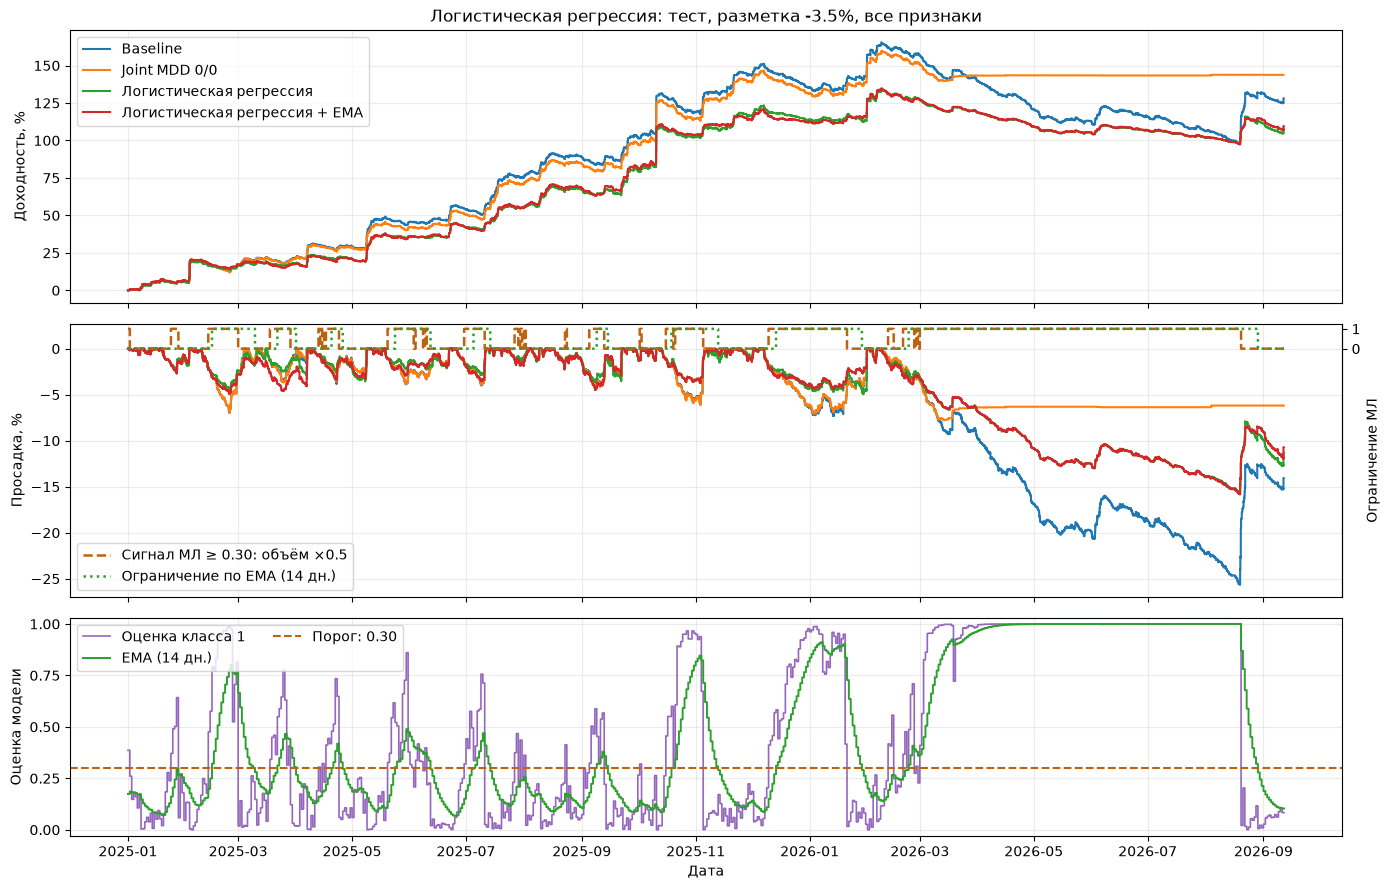

In [8]:
study_1 = run_study(labels_1, -3.5, smoothing=True)

### Моделирование: способ 2 (−2%)

ML: порог сигнала 0.45, объём ×0.5.


Threshold  Reduced_multiplier  Selected  \
Method                  Config_ID                                            
Baseline                0                NaN                1.00     False   
Логистическая регрессия 10              0.45                0.50      True   
                        1               0.30                0.50     False   
                        7               0.40                0.50     False   
                        4               0.35                0.50     False   
                        13              0.50                0.50     False   
                        16              0.55                0.50     False   
                        19              0.60                0.50     False   
                        11              0.45                0.75     False   
                        22              0.65                0.50     False   
                        20              0.60                0.75     False   
                        2               0.30                0.75     False   
                        8               0.40                0.75     False   
                        25              0.70                0.50     False   
                        14              0.50                0.75     False   
                        17              0.55                0.75     False   
                        5               0.35                0.75     False   
                        23              0.65                0.75     False   
                        26              0.70                0.75     False   
                        18              0.60                0.00     False   
                        12              0.50                0.00     False   
                        9               0.45                0.00     False   
                        21              0.65                0.00     False   
                        24              0.70                0.00     False   
                        15              0.55                0.00     False   
                        6               0.40                0.00     False   
                        0               0.30                0.00     False   
                        3               0.35                0.00     False   

                                   Net_PnL_USDT  PnL_delta_USDT  \
Method                  Config_ID                                 
Baseline                0            131068.914           0.000   
Логистическая регрессия 10           110329.664      -20739.250   
                        1            100652.090      -30416.824   
                        7            100573.466      -30495.448   
                        4             99131.675      -31937.239   
                        13           110440.022      -20628.892   
                        16           109563.832      -21505.082   
                        19           116268.602      -14800.312   
                        11           120699.289      -10369.625   
                        22           114791.845      -16277.069   
                        20           123668.758       -7400.156   
                        2            115860.502      -15208.412   
                        8            115821.190      -15247.724   
                        25           115483.010      -15585.904   
                        14           120754.468      -10314.446   
                        17           120316.373      -10752.541   
                        5            115100.295      -15968.619   
                        23           122930.379       -8138.535   
                        26           123275.962       -7792.952   
                        18           101468.289      -29600.625   
                        12            89811.130      -41257.784   
                        9             89590.414      -41478.500   
                        21            98514.776      -32554.138   
                   

,Дней,Дней класса 1,Эпизодов класса 1,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC AUC,Average precision,Brier,TN,FP,FN,TP
Period,,,,,,,,,,,,,,,
Валидация 2024,356.0,133.0,10.0,0.829,0.800,0.827,0.684,0.749,0.894,0.825,0.129,204.0,19.0,42.0,91.0
Тест 2025,357.0,144.0,9.0,0.818,0.822,0.742,0.840,0.788,0.899,0.864,0.123,171.0,42.0,23.0,121.0
Тест 2026,231.0,205.0,2.0,0.939,0.832,0.961,0.971,0.966,0.957,0.994,0.048,18.0,8.0,6.0,199.0


Start_USDT    End_USDT  Net_PnL_USDT  \
Year Method                                                          
2025 Baseline                 209873.135  494037.906    284164.771   
     Joint MDD 0/0            209873.135  485939.882    276066.747   
     Логистическая регрессия  209873.135  434467.379    224594.244   
2026 Baseline                 494037.906  478801.108    -15236.798   
     Joint MDD 0/0            485939.882  511593.215     25653.333   
     Логистическая регрессия  434467.379  425837.543     -8629.836   

                              PnL_retained_pct  PnL_delta_USDT  Return_pct  \
Year Method                                                                  
2025 Baseline                          100.000           0.000     135.398   
     Joint MDD 0/0                      97.150       -8098.024     131.540   
     Логистическая регрессия            79.037      -59570.527     107.014   
2026 Baseline                              NaN           0.000      -3.084   
     Joint MDD 0/0                         NaN       40890.131       5.279   
     Логистическая регрессия               NaN        6606.963      -1.986   

                              CAGR_pct  MDD_pct  DaR95_pct  CDaR95_pct  \
Year Method                                                              
2025 Baseline                  135.536    6.967      4.801       5.498   
     Joint MDD 0/0             131.673    6.956      4.896       5.507   
     Логистическая регрессия   107.117    4.310      3.161       3.437   
2026 Baseline                   -4.405   25.659     22.605      23.954   
     Joint MDD 0/0               7.678    7.760      6.421       7.180   
     Логистическая регрессия    -2.844   15.671     13.784      14.545   

                              Calmar  RecoveryFactor  Sharpe  Sortino  \
Year Method                                                             
2025 Baseline                 19.455           8.382   3.797   15.929   
     Joint MDD 0/0            18.928           8.491   3.755   15.687   
     Логистическая регрессия  24.855          11.488   3.640   15.961   
2026 Baseline                 -0.172          -0.107  -0.198   -0.514   
     Joint MDD 0/0             0.989           0.606   0.924    2.446   
     Логистическая регрессия  -0.181          -0.115  -0.192   -0.531   

                              Max_DD_duration_days  Time_underwater_pct  \
Year Method                                                               
2025 Baseline                                 36.0               76.164   
     Joint MDD 0/0                            36.0               76.438   
     Логистическая регрессия                  36.0               78.630   
2026 Baseline                                215.0               95.669   
     Joint MDD 0/0                           215.0               94.882   
     Логистическая регрессия                 215.0               96.063   

                              Serious_DD_count  Serious_DD_days  \
Year Method                                                       
2025 Baseline                              8.0             58.0   
     Joint MDD 0/0                         8.0             57.0   
     Логистическая регрессия               4.0             27.0   
2026 Baseline                              1.0            198.0   
     Joint MDD 0/0                         1.0            199.0   
     Логистическая регрессия               1.0            194.0   

                              Avg_multiplier  Trades_half_pct  \
Year Method                                                     
2025 Baseline                          1.000            0.000   
     Joint MDD 0/0                     0.982            0.000   
     Логистическая регрессия           0.776           44.890   
2026 Baseline                          1.000            0.000   
     Joint MDD 0/0                     0.254            0.000   
     Логистическая регрессия           0.591           81.731   

       

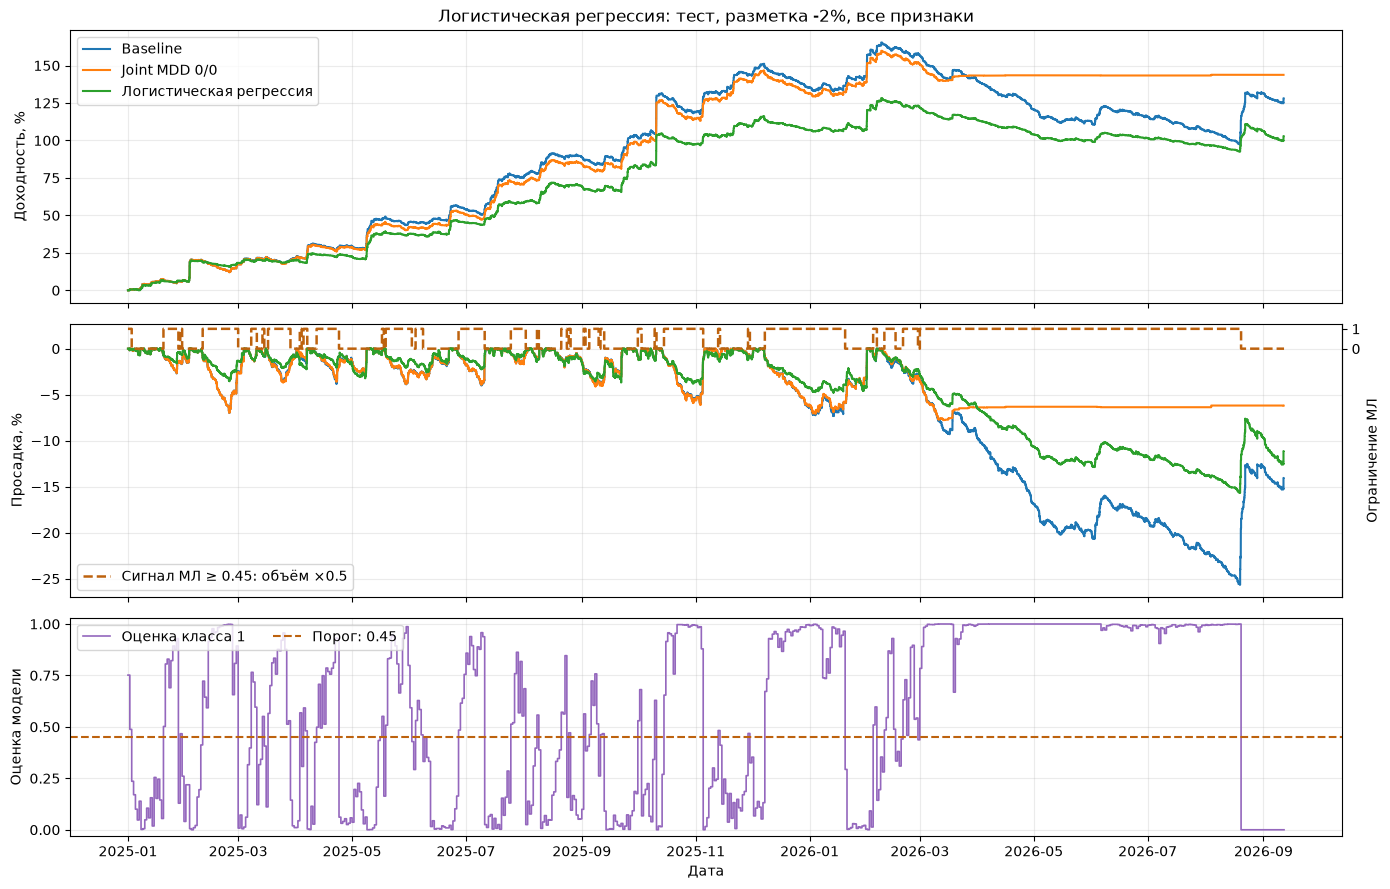

In [9]:
study_2 = run_study(labels_2, -2.0)

### Моделирование: способ 3 (−5%)

ML: порог сигнала 0.30, объём ×0.5.


Threshold  Reduced_multiplier  Selected  \
Method                  Config_ID                                            
Baseline                0                NaN                1.00     False   
Логистическая регрессия 1               0.30                0.50      True   
                        4               0.35                0.50     False   
                        10              0.45                0.50     False   
                        9               0.45                0.00     False   
                        7               0.40                0.50     False   
                        2               0.30                0.75     False   
                        11              0.45                0.75     False   
                        5               0.35                0.75     False   
                        3               0.35                0.00     False   
                        8               0.40                0.75     False   
                        6               0.40                0.00     False   
                        12              0.50                0.00     False   
                        18              0.60                0.00     False   
                        13              0.50                0.50     False   
                        15              0.55                0.00     False   
                        19              0.60                0.50     False   
                        16              0.55                0.50     False   
                        20              0.60                0.75     False   
                        14              0.50                0.75     False   
                        17              0.55                0.75     False   
                        23              0.65                0.75     False   
                        22              0.65                0.50     False   
                        26              0.70                0.75     False   
                        25              0.70                0.50     False   
                        21              0.65                0.00     False   
                        24              0.70                0.00     False   
                        0               0.30                0.00     False   

                                   Net_PnL_USDT  PnL_delta_USDT  \
Method                  Config_ID                                 
Baseline                0            131068.914           0.000   
Логистическая регрессия 1            115196.156      -15872.758   
                        4            121898.960       -9169.954   
                        10           127558.780       -3510.134   
                        9            124048.646       -7020.268   
                        7            124089.595       -6979.319   
                        2            123132.535       -7936.379   
                        11           129313.847       -1755.067   
                        5            126483.937       -4584.977   
                        3            112729.006      -18339.908   
                        8            127579.254       -3489.660   
                        6            117110.275      -13958.639   
                        12           124380.311       -6688.603   
                        18           124064.527       -7004.387   
                        13           127724.612       -3344.302   
                        15           124182.079       -6886.835   
                        19           127566.721       -3502.193   
                        16           127625.496       -3443.418   
                        20           129317.817       -1751.097   
                        14           129396.763       -1672.151   
                        17           129347.205       -1721.709   
                        23           129211.986       -1856.928   
                        22           127355.058       -3713.856   
                   

,Дней,Дней класса 1,Эпизодов класса 1,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC AUC,Average precision,Brier,TN,FP,FN,TP
Period,,,,,,,,,,,,,,,
Валидация 2024,356.0,33.0,1.0,0.896,0.902,0.469,0.909,0.619,0.908,0.488,0.066,289.0,34.0,3.0,30.0
Тест 2025,357.0,65.0,3.0,0.804,0.767,0.474,0.708,0.568,0.866,0.706,0.093,241.0,51.0,19.0,46.0
Тест 2026,231.0,205.0,2.0,0.909,0.831,0.965,0.932,0.948,0.957,0.994,0.078,19.0,7.0,14.0,191.0


Start_USDT    End_USDT  Net_PnL_USDT  \
Year Method                                                          
2025 Baseline                 209873.135  494037.906    284164.771   
     Joint MDD 0/0            209873.135  485939.882    276066.747   
     Логистическая регрессия  209873.135  451000.019    241126.883   
2026 Baseline                 494037.906  478801.108    -15236.798   
     Joint MDD 0/0            485939.882  511593.215     25653.333   
     Логистическая регрессия  451000.019  434386.458    -16613.560   

                              PnL_retained_pct  PnL_delta_USDT  Return_pct  \
Year Method                                                                  
2025 Baseline                          100.000           0.000     135.398   
     Joint MDD 0/0                      97.150       -8098.024     131.540   
     Логистическая регрессия            84.855      -43037.888     114.892   
2026 Baseline                              NaN           0.000      -3.084   
     Joint MDD 0/0                         NaN       40890.131       5.279   
     Логистическая регрессия               NaN       -1376.762      -3.684   

                              CAGR_pct  MDD_pct  DaR95_pct  CDaR95_pct  \
Year Method                                                              
2025 Baseline                  135.536    6.967      4.801       5.498   
     Joint MDD 0/0             131.673    6.956      4.896       5.507   
     Логистическая регрессия   115.004    4.525      3.416       3.711   
2026 Baseline                   -4.405   25.659     22.605      23.954   
     Joint MDD 0/0               7.678    7.760      6.421       7.180   
     Логистическая регрессия    -5.254   16.551     14.724      15.462   

                              Calmar  RecoveryFactor  Sharpe  Sortino  \
Year Method                                                             
2025 Baseline                 19.455           8.382   3.797   15.929   
     Joint MDD 0/0            18.928           8.491   3.755   15.687   
     Логистическая регрессия  25.413          12.659   3.472   15.395   
2026 Baseline                 -0.172          -0.107  -0.198   -0.514   
     Joint MDD 0/0             0.989           0.606   0.924    2.446   
     Логистическая регрессия  -0.317          -0.203  -0.414   -1.089   

                              Max_DD_duration_days  Time_underwater_pct  \
Year Method                                                               
2025 Baseline                                 36.0               76.164   
     Joint MDD 0/0                            36.0               76.438   
     Логистическая регрессия                  37.0               80.548   
2026 Baseline                                215.0               95.669   
     Joint MDD 0/0                           215.0               94.882   
     Логистическая регрессия                 215.0               96.457   

                              Serious_DD_count  Serious_DD_days  \
Year Method                                                       
2025 Baseline                              8.0             58.0   
     Joint MDD 0/0                         8.0             57.0   
     Логистическая регрессия               5.0             47.0   
2026 Baseline                              1.0            198.0   
     Joint MDD 0/0                         1.0            199.0   
     Логистическая регрессия               1.0            198.0   

                              Avg_multiplier  Trades_half_pct  \
Year Method                                                     
2025 Baseline                          1.000            0.000   
     Joint MDD 0/0                     0.982            0.000   
     Логистическая регрессия           0.863           27.402   
2026 Baseline                          1.000            0.000   
     Joint MDD 0/0                     0.254            0.000   
     Логистическая регрессия           0.612           77.503   

       

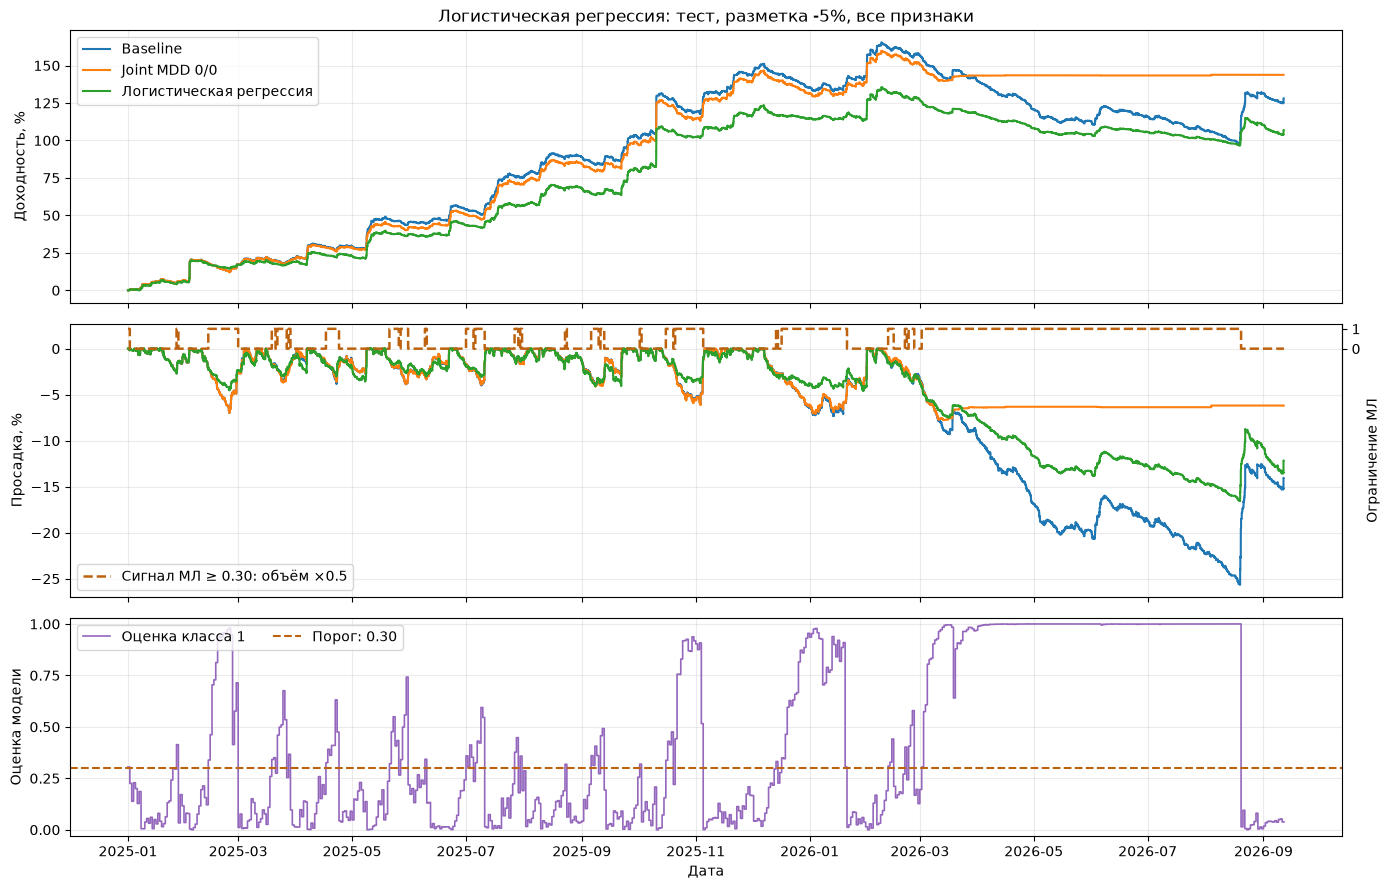

In [10]:
study_3 = run_study(labels_3, -5.0)

### Моделирование: способ 1 (−3,5%), только глубина просадки

Контрольный логрег с одним признаком: глубина просадки портфеля на начало дня. Разметка, даты и сетка управления те же, что у модели с 17 признаками. При одном признаке порог оценки логрега задаёт эквивалентный порог глубины, если коэффициент ненулевой.

ML: порог сигнала 0.40, объём ×0.5.


Threshold  Reduced_multiplier  Selected  \
Method                  Config_ID                                            
Baseline                0                NaN                1.00     False   
Логистическая регрессия 7               0.40                0.50      True   
                        10              0.45                0.50     False   
                        1               0.30                0.50     False   
                        4               0.35                0.50     False   
                        16              0.55                0.50     False   
                        13              0.50                0.50     False   
                        25              0.70                0.50     False   
                        24              0.70                0.00     False   
                        11              0.45                0.75     False   
                        8               0.40                0.75     False   
                        18              0.60                0.00     False   
                        2               0.30                0.75     False   
                        19              0.60                0.50     False   
                        17              0.55                0.75     False   
                        5               0.35                0.75     False   
                        22              0.65                0.50     False   
                        14              0.50                0.75     False   
                        26              0.70                0.75     False   
                        21              0.65                0.00     False   
                        20              0.60                0.75     False   
                        23              0.65                0.75     False   
                        9               0.45                0.00     False   
                        6               0.40                0.00     False   
                        15              0.55                0.00     False   
                        0               0.30                0.00     False   
                        12              0.50                0.00     False   
                        3               0.35                0.00     False   

                                   Net_PnL_USDT  PnL_delta_USDT  \
Method                  Config_ID                                 
Baseline                0            131068.914           0.000   
Логистическая регрессия 7            124086.541       -6982.373   
                        10           124086.904       -6982.010   
                        1            115964.673      -15104.241   
                        4            115583.093      -15485.821   
                        16           124246.700       -6822.214   
                        13           123941.449       -7127.465   
                        25           128041.198       -3027.716   
                        24           125013.482       -6055.432   
                        11           127577.909       -3491.005   
                        8            127577.728       -3491.187   
                        18           123434.795       -7634.119   
                        2            123516.793       -7552.121   
                        19           127251.855       -3817.059   
                        17           127657.807       -3411.107   
                        5            123326.003       -7742.911   
                        22           127680.790       -3388.124   
                        14           127505.181       -3563.733   
                        26           129555.056       -1513.858   
                        21           124292.666       -6776.248   
                        20           129160.384       -1908.530   
                        23           129374.852       -1694.062   
                        9            117104.893      -13964.021   
                   

,Дней,Дней класса 1,Эпизодов класса 1,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC AUC,Average precision,Brier,TN,FP,FN,TP
Period,,,,,,,,,,,,,,,
Валидация 2024,356.0,44.0,2.0,0.921,0.799,0.700,0.636,0.667,0.875,0.656,0.073,300.0,12.0,16.0,28.0
Тест 2025,357.0,136.0,8.0,0.706,0.642,0.718,0.375,0.493,0.778,0.670,0.206,201.0,20.0,85.0,51.0
Тест 2026,231.0,205.0,2.0,0.861,0.620,0.914,0.932,0.923,0.906,0.988,0.093,8.0,18.0,14.0,191.0


Start_USDT    End_USDT  Net_PnL_USDT  \
Year Method                                                          
2025 Baseline                 209873.135  494037.906    284164.771   
     Joint MDD 0/0            209873.135  485939.882    276066.747   
     Логистическая регрессия  209873.135  445787.745    235914.610   
2026 Baseline                 494037.906  478801.108    -15236.798   
     Joint MDD 0/0            485939.882  511593.215     25653.333   
     Логистическая регрессия  445787.745  430480.710    -15307.034   

                              PnL_retained_pct  PnL_delta_USDT  Return_pct  \
Year Method                                                                  
2025 Baseline                           100.00           0.000     135.398   
     Joint MDD 0/0                       97.15       -8098.024     131.540   
     Логистическая регрессия             83.02      -48250.161     112.408   
2026 Baseline                              NaN           0.000      -3.084   
     Joint MDD 0/0                         NaN       40890.131       5.279   
     Логистическая регрессия               NaN         -70.236      -3.434   

                              CAGR_pct  MDD_pct  DaR95_pct  CDaR95_pct  \
Year Method                                                              
2025 Baseline                  135.536    6.967      4.801       5.498   
     Joint MDD 0/0             131.673    6.956      4.896       5.507   
     Логистическая регрессия   112.518    5.047      3.966       4.357   
2026 Baseline                   -4.405   25.659     22.605      23.954   
     Joint MDD 0/0               7.678    7.760      6.421       7.180   
     Логистическая регрессия    -4.900   16.460     14.565      15.330   

                              Calmar  RecoveryFactor  Sharpe  Sortino  \
Year Method                                                             
2025 Baseline                 19.455           8.382   3.797   15.929   
     Joint MDD 0/0            18.928           8.491   3.755   15.687   
     Логистическая регрессия  22.295          10.646   3.404   14.016   
2026 Baseline                 -0.172          -0.107  -0.198   -0.514   
     Joint MDD 0/0             0.989           0.606   0.924    2.446   
     Логистическая регрессия  -0.298          -0.195  -0.502   -1.178   

                              Max_DD_duration_days  Time_underwater_pct  \
Year Method                                                               
2025 Baseline                                 36.0               76.164   
     Joint MDD 0/0                            36.0               76.438   
     Логистическая регрессия                  56.0               81.370   
2026 Baseline                                215.0               95.669   
     Joint MDD 0/0                           215.0               94.882   
     Логистическая регрессия                 215.0               96.063   

                              Serious_DD_count  Serious_DD_days  \
Year Method                                                       
2025 Baseline                              8.0             58.0   
     Joint MDD 0/0                         8.0             57.0   
     Логистическая регрессия               7.0             66.0   
2026 Baseline                              1.0            198.0   
     Joint MDD 0/0                         1.0            199.0   
     Логистическая регрессия               1.0            201.0   

                              Avg_multiplier  Trades_half_pct  \
Year Method                                                     
2025 Baseline                          1.000            0.000   
     Joint MDD 0/0                     0.982            0.000   
     Логистическая регрессия           0.902           19.512   
2026 Baseline                          1.000            0.000   
     Joint MDD 0/0                     0.254            0.000   
     Логистическая регрессия           0.540           91.982   

       

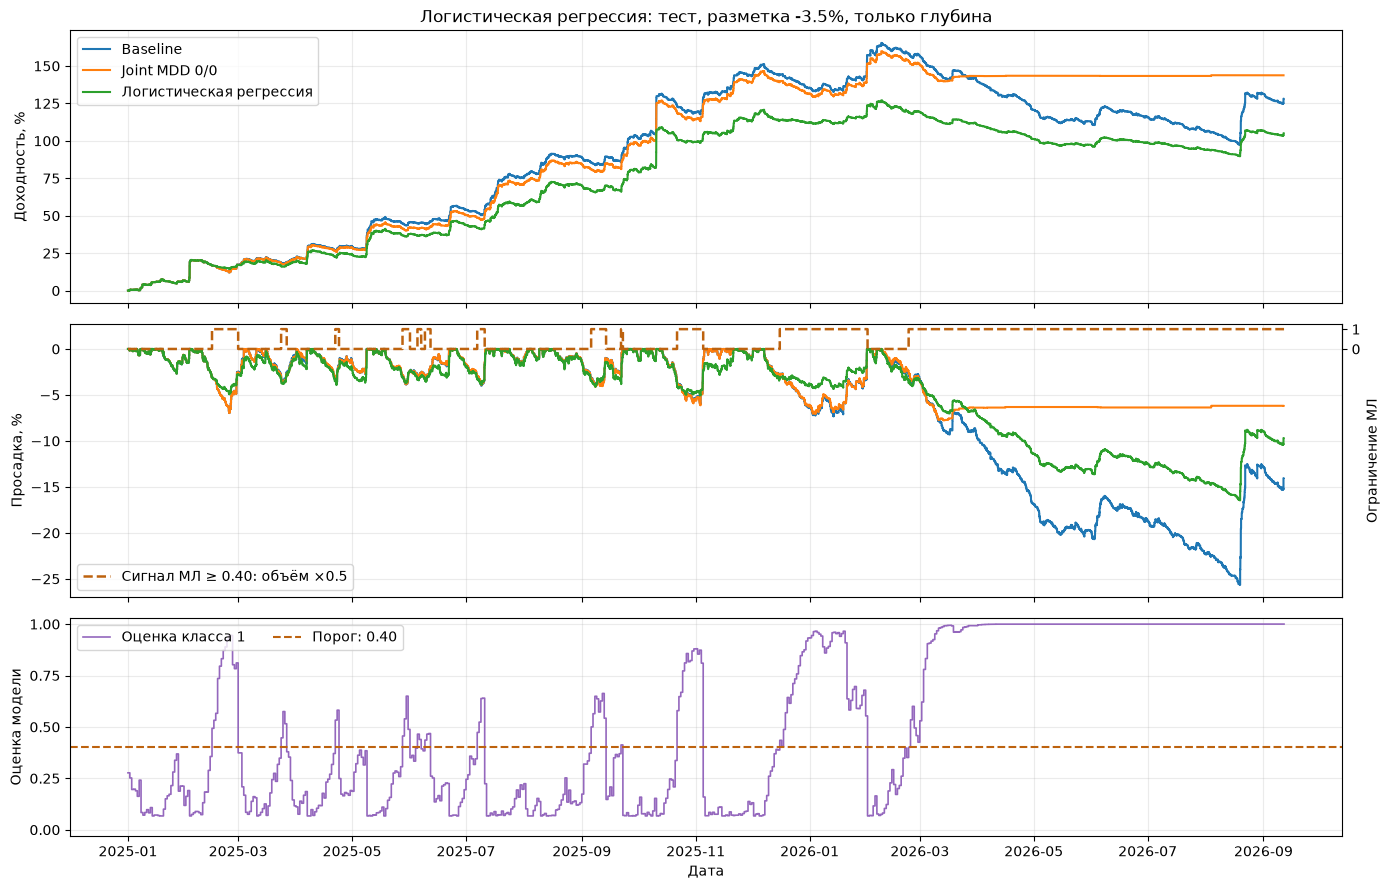

Эквивалентное условие: текущая просадка ≤ -2.65%.


In [11]:
study_depth_only = run_study(labels_1, -3.5, feature_columns=['drawdown_pct'])

depth_model = study_depth_only['model']
depth_score_threshold = study_depth_only['threshold']
depth_coefficient = depth_model[-1].coef_[0, 0] / depth_model[1].scale_[0]
if abs(depth_coefficient) > 1e-12:
    depth_logit = np.log(depth_score_threshold / (1 - depth_score_threshold))
    depth_drawdown_threshold = (
        depth_model[1].mean_[0] + (depth_logit - depth_model[-1].intercept_[0]) / depth_coefficient
    )
    depth_operator = '≤' if depth_coefficient < 0 else '≥'
    print(f'Эквивалентное условие: текущая просадка {depth_operator} {depth_drawdown_threshold:.2f}%.')

### Моделирование: градиентный бустинг (−3,5%)

Модель обучаем на 2021–2023 со стандартными настройками. На 2024 подбираем только порог сигнала и объём новых позиций; итоговая проверка — на 2025–2026.

ML: порог сигнала 0.50, объём ×0.75.


Threshold  Reduced_multiplier  Selected  \
Method              Config_ID                                            
Baseline            0                NaN                1.00     False   
Градиентный бустинг 14              0.50                0.75      True   
                    11              0.45                0.75     False   
                    26              0.70                0.75     False   
                    17              0.55                0.75     False   
                    23              0.65                0.75     False   
                    13              0.50                0.50     False   
                    20              0.60                0.75     False   
                    8               0.40                0.75     False   
                    5               0.35                0.75     False   
                    25              0.70                0.50     False   
                    10              0.45                0.50     False   
                    2               0.30                0.75     False   
                    16              0.55                0.50     False   
                    22              0.65                0.50     False   
                    19              0.60                0.50     False   
                    7               0.40                0.50     False   
                    12              0.50                0.00     False   
                    4               0.35                0.50     False   
                    1               0.30                0.50     False   
                    24              0.70                0.00     False   
                    9               0.45                0.00     False   
                    15              0.55                0.00     False   
                    21              0.65                0.00     False   
                    18              0.60                0.00     False   
                    6               0.40                0.00     False   
                    3               0.35                0.00     False   
                    0               0.30                0.00     False   

                               Net_PnL_USDT  PnL_delta_USDT  PnL_retained_pct  \
Method              Config_ID                                                   
Baseline            0            131068.914           0.000           100.000   
Градиентный бустинг 14           125882.230       -5186.684            96.043   
                    11           124473.887       -6595.027            94.968   
                    26           126217.785       -4851.129            96.299   
                    17           125557.492       -5511.422            95.795   
                    23           125376.411       -5692.503            95.657   
                    13           120695.547      -10373.367            92.086   
                    20           125375.387       -5693.527            95.656   
                    8            124484.317       -6584.597            94.976   
                    5            122445.466       -8623.448            93.421   
                    25           121366.656       -9702.258            92.598   
                    10           117878.859      -13190.055            89.937   
                    2            121745.718       -9323.196            92.887   
                    16           120046.069      -11022.845            91.590   
                    22           119683.909      -11385.005            91.314   
                    19           119681.860      -11387.054            91.312   
                    7            117899.719      -13169.195            89.952   
                    12           110322.180      -20746.735            84.171   
                    4            113822.018      -17246.896            86.841   
                    1            112422.522      -18646.392            85.774   
                    24      

,Дней,Дней класса 1,Эпизодов класса 1,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC AUC,Average precision,Brier,TN,FP,FN,TP
Period,,,,,,,,,,,,,,,
Валидация 2024,356.0,44.0,2.0,0.876,0.676,0.500,0.409,0.450,0.820,0.476,0.098,294.0,18.0,26.0,18.0
Тест 2025,357.0,136.0,8.0,0.706,0.642,0.718,0.375,0.493,0.800,0.692,0.212,201.0,20.0,85.0,51.0
Тест 2026,231.0,205.0,2.0,0.619,0.769,0.992,0.576,0.728,0.818,0.976,0.310,25.0,1.0,87.0,118.0


Start_USDT    End_USDT  Net_PnL_USDT  \
Year Method                                                      
2025 Baseline             209873.135  494037.906    284164.771   
     Joint MDD 0/0        209873.135  485939.882    276066.747   
     Градиентный бустинг  209873.135  464161.317    254288.182   
2026 Baseline             494037.906  478801.108    -15236.798   
     Joint MDD 0/0        485939.882  511593.215     25653.333   
     Градиентный бустинг  464161.317  444372.164    -19789.153   

                          PnL_retained_pct  PnL_delta_USDT  Return_pct  \
Year Method                                                              
2025 Baseline                      100.000           0.000     135.398   
     Joint MDD 0/0                  97.150       -8098.024     131.540   
     Градиентный бустинг            89.486      -29876.589     121.163   
2026 Baseline                          NaN           0.000      -3.084   
     Joint MDD 0/0                     NaN       40890.131       5.279   
     Градиентный бустинг               NaN       -4552.355      -4.263   

                          CAGR_pct  MDD_pct  DaR95_pct  CDaR95_pct  Calmar  \
Year Method                                                                  
2025 Baseline              135.536    6.967      4.801       5.498  19.455   
     Joint MDD 0/0         131.673    6.956      4.896       5.507  18.928   
     Градиентный бустинг   121.283    6.119      4.700       5.157  19.821   
2026 Baseline               -4.405   25.659     22.605      23.954  -0.172   
     Joint MDD 0/0           7.678    7.760      6.421       7.180   0.989   
     Градиентный бустинг    -6.073   23.697     21.157      22.283  -0.256   

                          RecoveryFactor  Sharpe  Sortino  \
Year Method                                                 
2025 Baseline                      8.382   3.797   15.929   
     Joint MDD 0/0                 8.491   3.755   15.687   
     Градиентный бустинг           9.247   3.545   14.729   
2026 Baseline                     -0.107  -0.198   -0.514   
     Joint MDD 0/0                 0.606   0.924    2.446   
     Градиентный бустинг          -0.159  -0.353   -0.890   

                          Max_DD_duration_days  Time_underwater_pct  \
Year Method                                                           
2025 Baseline                             36.0               76.164   
     Joint MDD 0/0                        36.0               76.438   
     Градиентный бустинг                  36.0               79.178   
2026 Baseline                            215.0               95.669   
     Joint MDD 0/0                       215.0               94.882   
     Градиентный бустинг                 215.0               95.669   

                          Serious_DD_count  Serious_DD_days  Avg_multiplier  \
Year Method                                                                   
2025 Baseline                          8.0             58.0           1.000   
     Joint MDD 0/0                     8.0             57.0           0.982   
     Градиентный бустинг               8.0             60.0           0.950   
2026 Baseline                          1.0            198.0           1.000   
     Joint MDD 0/0                     1.0            199.0           0.254   
     Градиентный бустинг               1.0            198.0           0.873   

                          Trades_half_pct  Trades_skipped_pct  Switches  \
Year Method                                                               
2025 Baseline                         0.0               0.000       0.0   
     Joint MDD 0/0                    0.0               1.781      37.0   
     Градиентный бустинг              0.0               0.000      41.0   
2026 Baseline                         0.0               0.000       0.0   
     Joint MDD 0/0                    0.0              74.630      98.0   
     Градиентный бустинг              0.0               0.000  

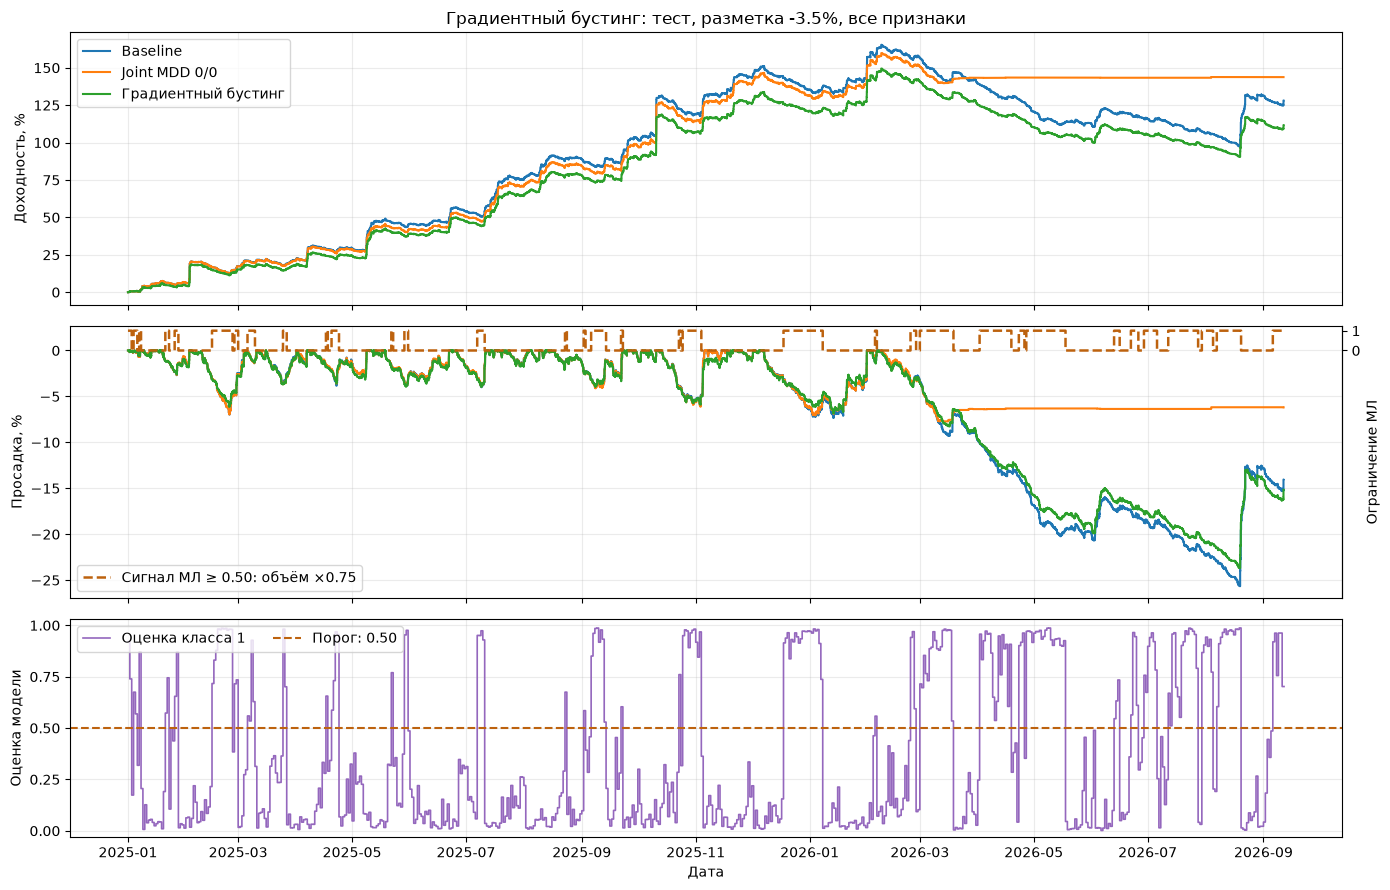

In [12]:
study_boosting = run_study(
    labels_1, -3.5, classifier=GradientBoostingClassifier(random_state=42),
    method_name='Градиентный бустинг'
)

### Моделирование: CatBoost (−3,5%)

Для CatBoost, HistGradientBoosting и AdaBoost оставляем базовые настройки моделей. Каждая модель обучается на 2021–2023 на тех же признаках; на 2024 по Calmar подбираем только порог сигнала и множитель размера новых позиций. Итоговая проверка — на 2025–2026, метрики отдельно по годам.

ML: порог сигнала 0.30, объём ×0.5.


Threshold  Reduced_multiplier  Selected  Net_PnL_USDT  \
Method   Config_ID                                                          
Baseline 0                NaN                1.00     False    131068.914   
CatBoost 1               0.30                0.50      True    118322.172   
         0               0.30                0.00     False    105575.430   
         2               0.30                0.75     False    124695.543   
         7               0.40                0.50     False    118050.833   
         4               0.35                0.50     False    117616.138   
         8               0.40                0.75     False    124559.873   
         5               0.35                0.75     False    124342.526   
         25              0.70                0.50     False    124891.160   
         24              0.70                0.00     False    118713.405   
         26              0.70                0.75     False    127980.037   
         23              0.65                0.75     False    126133.010   
         22              0.65                0.50     False    121197.106   
         11              0.45                0.75     False    124760.013   
         10              0.45                0.50     False    118451.111   
         21              0.65                0.00     False    111325.297   
         17              0.55                0.75     False    124690.547   
         20              0.60                0.75     False    124534.789   
         14              0.50                0.75     False    124801.815   
         6               0.40                0.00     False    105032.752   
         3               0.35                0.00     False    104163.361   
         16              0.55                0.50     False    118312.180   
         19              0.60                0.50     False    118000.664   
         9               0.45                0.00     False    105833.308   
         13              0.50                0.50     False    118534.717   
         15              0.55                0.00     False    105555.447   
         18              0.60                0.00     False    104932.414   
         12              0.50                0.00     False    106000.519   

                    PnL_delta_USDT  PnL_retained_pct  Return_pct  MDD_pct  \
Method   Config_ID                                                          
Baseline 0                   0.000           100.000     166.322    5.668   
CatBoost 1              -12746.742            90.275     150.147    4.343   
         0              -25493.484            80.550     133.972    3.902   
         2               -6373.371            95.137     158.235    5.012   
         7              -13018.081            90.068     149.803    4.900   
         4              -13452.776            89.736     149.251    4.900   
         8               -6509.041            95.034     158.062    5.259   
         5               -6726.388            94.868     157.787    5.259   
         25              -6177.754            95.287     158.483    5.307   
         24             -12355.509            90.573     150.643    5.072   
         26              -3088.877            97.643     162.403    5.488   
         23              -4935.904            96.234     160.059    5.415   
         22              -9871.808            92.468     153.795    5.209   
         11              -6308.902            95.187     158.316    5.398   
         10             -12617.803            90.373     150.311    5.169   
         21             -19743.617            84.936     141.268    4.875   
         17              -6378.367            95.134     158.228    5.475   
         20              -6534.125            95.015     158.031    5.470   
         14              -6267.099            95.218     158.369    5.488   
         6              -26036.162            80.136     133.283    4.661   
         3     

,Net_PnL_USDT,MDD_pct,Calmar,Selected
EMA_span_days,,,,
14,116886.177,3.849,38.420,True
7,113522.819,3.789,37.903,False
5,115591.788,4.133,35.384,False
3,115318.117,4.441,32.849,False


Дней  Дней класса 1  Эпизодов класса 1  \
Method         Period                                                    
CatBoost       Валидация 2024  356.0           44.0                2.0   
               Тест 2025       357.0          136.0                8.0   
               Тест 2026       231.0          205.0                2.0   
CatBoost + EMA Валидация 2024  356.0           44.0                2.0   
               Тест 2025       357.0          136.0                8.0   
               Тест 2026       231.0          205.0                2.0   

                               Accuracy  Balanced accuracy  Precision  Recall  \
Method         Period                                                           
CatBoost       Валидация 2024     0.888              0.770      0.540   0.614   
               Тест 2025          0.739              0.693      0.731   0.500   
               Тест 2026          0.723              0.777      0.973   0.707   
CatBoost + EMA Валидация 2024     0.882              0.737      0.522   0.545   
               Тест 2025          0.588              0.535      0.442   0.309   
               Тест 2026          0.818              0.763      0.955   0.834   

                                  F1  ROC AUC  Average precision  Brier  \
Method         Period                                                     
CatBoost       Валидация 2024  0.574    0.856              0.550  0.085   
               Тест 2025       0.594    0.843              0.755  0.198   
               Тест 2026       0.819    0.845              0.978  0.256   
CatBoost + EMA Валидация 2024  0.533    0.728              0.465  0.088   
               Тест 2025       0.364    0.566              0.488  0.264   
               Тест 2026       0.891    0.886              0.985  0.199   

                                  TN    FP    FN     TP  
Method         Period                                    
CatBoost       Валидация 2024  289.0  23.0  17.0   27.0  
               Тест 2025       196.0  25.0  68.0   68.0  
               Тест 2026        22.0   4.0  60.0  145.0  
CatBoost + EMA Валидация 2024  290.0  22.0  20.0   24.0  
               Тест 2025       168.0  53.0  94.0   42.0  
               Тест 2026        18.0   8.0  34.0  171.0

Start_USDT    End_USDT  Net_PnL_USDT  PnL_retained_pct  \
Year Method                                                                   
2025 Baseline        209873.135  494037.906    284164.771           100.000   
     Joint MDD 0/0   209873.135  485939.882    276066.747            97.150   
     CatBoost        209873.135  441268.511    231395.376            81.430   
     CatBoost + EMA  209873.135  427540.449    217667.314            76.599   
2026 Baseline        494037.906  478801.108    -15236.798               NaN   
     Joint MDD 0/0   485939.882  511593.215     25653.333               NaN   
     CatBoost        441268.511  420602.605    -20665.906               NaN   
     CatBoost + EMA  427540.449  418362.417     -9178.033               NaN   

                     PnL_delta_USDT  Return_pct  CAGR_pct  MDD_pct  DaR95_pct  \
Year Method                                                                     
2025 Baseline                 0.000     135.398   135.536    6.967      4.801   
     Joint MDD 0/0        -8098.024     131.540   131.673    6.956      4.896   
     CatBoost            -52769.395     110.255   110.362    5.073      3.956   
     CatBoost + EMA      -66497.457     103.714   103.813    5.891      4.459   
2026 Baseline                 0.000      -3.084    -4.405   25.659     22.605   
     Joint MDD 0/0        40890.131       5.279     7.678    7.760      6.421   
     CatBoost             -5429.108      -4.683    -6.665   20.471     18.624   
     CatBoost + EMA        6058.765      -2.147    -3.072   17.707     15.806   

                     CDaR95_pct  Calmar  RecoveryFactor  Sharpe  Sortino  \
Year Method                                                                
2025 Baseline             5.498  19.455           8.382   3.797   15.929   
     Joint MDD 0/0        5.507  18.928           8.491   3.755   15.687   
     CatBoost             4.307  21.754          10.443   3.363   14.327   
     CatBoost + EMA       5.012  17.623           8.485   3.210   13.156   
2026 Baseline            23.954  -0.172          -0.107  -0.198   -0.514   
     Joint MDD 0/0        7.180   0.989           0.606   0.924    2.446   
     CatBoost            19.391  -0.326          -0.204  -0.472   -1.189   
     CatBoost + EMA      16.575  -0.174          -0.109  -0.205   -0.541   

                     Max_DD_duration_days  Time_underwater_pct  \
Year Method                                                      
2025 Baseline                        36.0               76.164   
     Joint MDD 0/0                   36.0               76.438   
     CatBoost                        38.0               81.096   
     CatBoost + EMA                  57.0               82.466   
2026 Baseline                       215.0               95.669   
     Joint MDD 0/0                  215.0               94.882   
     CatBoost                       215.0               95.669   
     CatBoost + EMA                 215.0               96.063   

                     Serious_DD_count  Serious_DD_days  Avg_multiplier  \
Year Method                                                              
2025 Baseline                     8.0             58.0           1.000   
     Joint MDD 0/0                8.0             57.0           0.982   
     CatBoost                     7.0             52.0           0.870   
     CatBoost + EMA               7.0             69.0           0.864   
2026 Baseline                     1.0            198.0           1.000   
     Joint MDD 0/0                1.0            199.0           0.254   
     CatBoost                     1.0            198.0           0.681   
     CatBoost + EMA               1.0            203.0           0.612   

                     Trades_half_pct  Trades_skipped_pct  Switches  \
Year Method                                                          
2025 Baseline                  0.000               0.000       0.0   
     Joint MDD 0/0             0.000          

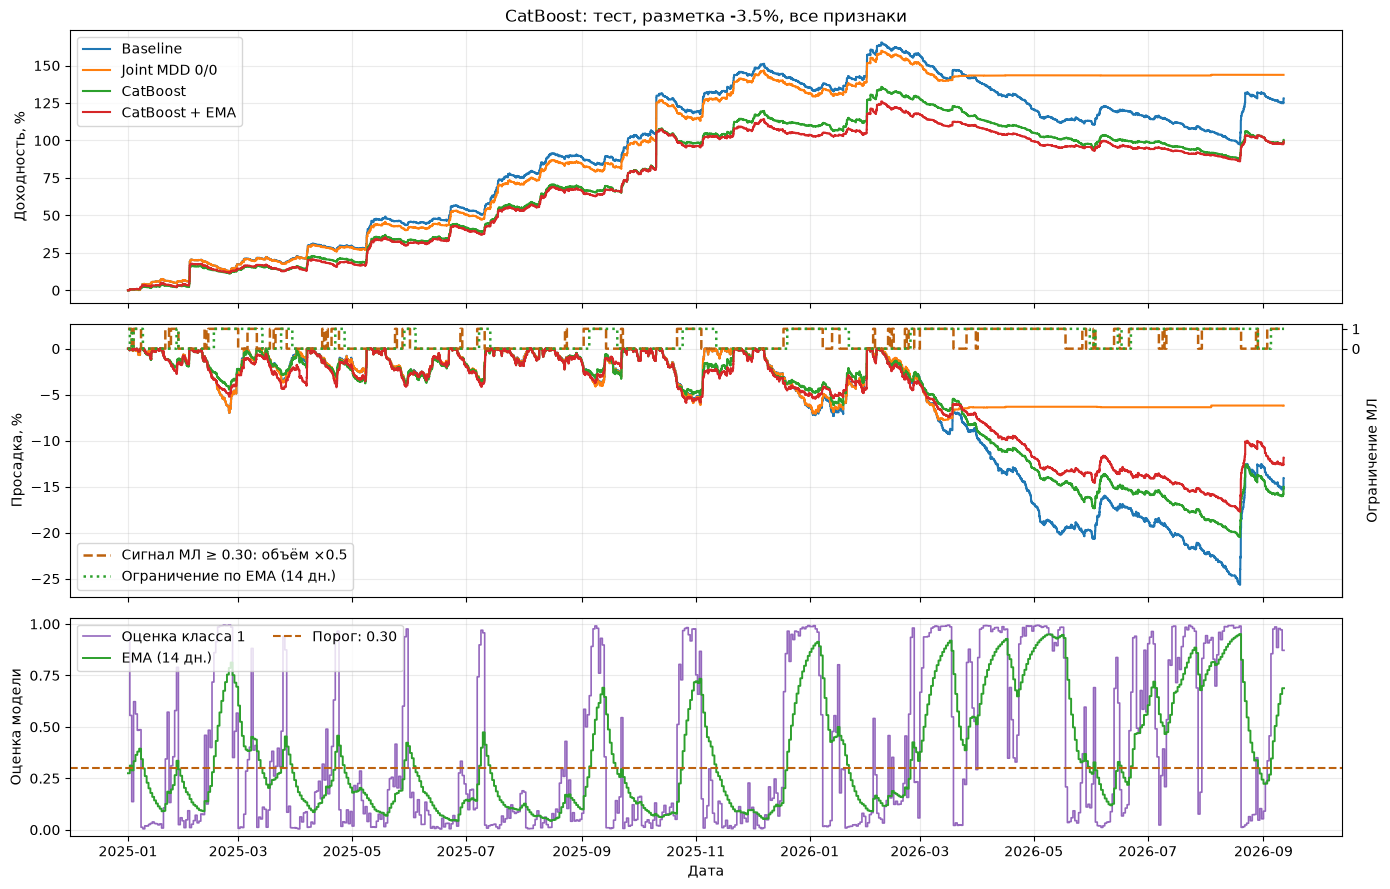

In [13]:
from catboost import CatBoostClassifier

study_catboost = run_study(
    labels_1, -3.5, classifier=CatBoostClassifier(random_seed=42, verbose=False, allow_writing_files=False),
    method_name='CatBoost', smoothing=True
)

### Моделирование: HistGradientBoosting (−3,5%)

ML: порог сигнала 0.45, объём ×0.75.


Threshold  Reduced_multiplier  Selected  \
Method               Config_ID                                            
Baseline             0                NaN                1.00     False   
HistGradientBoosting 11              0.45                0.75      True   
                     14              0.50                0.75     False   
                     8               0.40                0.75     False   
                     23              0.65                0.75     False   
                     26              0.70                0.75     False   
                     17              0.55                0.75     False   
                     20              0.60                0.75     False   
                     22              0.65                0.50     False   
                     25              0.70                0.50     False   
                     19              0.60                0.50     False   
                     5               0.35                0.75     False   
                     10              0.45                0.50     False   
                     2               0.30                0.75     False   
                     13              0.50                0.50     False   
                     7               0.40                0.50     False   
                     16              0.55                0.50     False   
                     21              0.65                0.00     False   
                     24              0.70                0.00     False   
                     4               0.35                0.50     False   
                     18              0.60                0.00     False   
                     1               0.30                0.50     False   
                     9               0.45                0.00     False   
                     12              0.50                0.00     False   
                     6               0.40                0.00     False   
                     15              0.55                0.00     False   
                     3               0.35                0.00     False   
                     0               0.30                0.00     False   

                                Net_PnL_USDT  PnL_delta_USDT  \
Method               Config_ID                                 
Baseline             0            131068.914           0.000   
HistGradientBoosting 11           125453.281       -5615.633   
                     14           125277.716       -5791.198   
                     8            125291.666       -5777.248   
                     23           126585.995       -4482.919   
                     26           126553.940       -4514.975   
                     17           125248.038       -5820.876   
                     20           126510.793       -4558.121   
                     22           122103.076       -8965.838   
                     25           122038.965       -9029.949   
                     19           121952.672       -9116.242   
                     5            122648.706       -8420.208   
                     10           119837.647      -11231.267   
                     2            122435.141       -8633.773   
                     13           119486.518      -11582.396   
                     7            119514.419      -11554.495   
                     16           119427.161      -11641.753   
                     21           113137.238      -17931.676   
                     24           113009.016      -18059.898   
                     4            114228.498      -16840.416   
                     18           112836.429      -18232.485   
                     1            113801.368      -17267.546   
                     9            108606.381      -22462.534   
                     12           107904.122      -23164.792   
                     6            107959.924      -23108.990   
                     15           107785.408      -23

,Дней,Дней класса 1,Эпизодов класса 1,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC AUC,Average precision,Brier,TN,FP,FN,TP
Period,,,,,,,,,,,,,,,
Валидация 2024,356.0,44.0,2.0,0.874,0.703,0.488,0.477,0.483,0.760,0.435,0.113,290.0,22.0,23.0,21.0
Тест 2025,357.0,136.0,8.0,0.714,0.655,0.724,0.404,0.519,0.772,0.702,0.244,200.0,21.0,81.0,55.0
Тест 2026,231.0,205.0,2.0,0.628,0.773,0.992,0.585,0.736,0.825,0.976,0.330,25.0,1.0,85.0,120.0


Start_USDT    End_USDT  Net_PnL_USDT  \
Year Method                                                       
2025 Baseline              209873.135  494037.906    284164.771   
     Joint MDD 0/0         209873.135  485939.882    276066.747   
     HistGradientBoosting  209873.135  472918.960    263045.825   
2026 Baseline              494037.906  478801.108    -15236.798   
     Joint MDD 0/0         485939.882  511593.215     25653.333   
     HistGradientBoosting  472918.960  450357.769    -22561.190   

                           PnL_retained_pct  PnL_delta_USDT  Return_pct  \
Year Method                                                               
2025 Baseline                       100.000           0.000     135.398   
     Joint MDD 0/0                   97.150       -8098.024     131.540   
     HistGradientBoosting            92.568      -21118.946     125.336   
2026 Baseline                           NaN           0.000      -3.084   
     Joint MDD 0/0                      NaN       40890.131       5.279   
     HistGradientBoosting               NaN       -7324.392      -4.771   

                           CAGR_pct  MDD_pct  DaR95_pct  CDaR95_pct  Calmar  \
Year Method                                                                   
2025 Baseline               135.536    6.967      4.801       5.498  19.455   
     Joint MDD 0/0          131.673    6.956      4.896       5.507  18.928   
     HistGradientBoosting   125.461    5.853      4.561       4.922  21.436   
2026 Baseline                -4.405   25.659     22.605      23.954  -0.172   
     Joint MDD 0/0            7.678    7.760      6.421       7.180   0.989   
     HistGradientBoosting    -6.788   23.816     21.350      22.424  -0.285   

                           RecoveryFactor  Sharpe  Sortino  \
Year Method                                                  
2025 Baseline                       8.382   3.797   15.929   
     Joint MDD 0/0                  8.491   3.755   15.687   
     HistGradientBoosting           9.542   3.669   15.588   
2026 Baseline                      -0.107  -0.198   -0.514   
     Joint MDD 0/0                  0.606   0.924    2.446   
     HistGradientBoosting          -0.178  -0.414   -1.039   

                           Max_DD_duration_days  Time_underwater_pct  \
Year Method                                                            
2025 Baseline                              36.0               76.164   
     Joint MDD 0/0                         36.0               76.438   
     HistGradientBoosting                  36.0               78.082   
2026 Baseline                             215.0               95.669   
     Joint MDD 0/0                        215.0               94.882   
     HistGradientBoosting                 215.0               95.669   

                           Serious_DD_count  Serious_DD_days  Avg_multiplier  \
Year Method                                                                    
2025 Baseline                           8.0             58.0           1.000   
     Joint MDD 0/0                      8.0             57.0           0.982   
     HistGradientBoosting               7.0             55.0           0.947   
2026 Baseline                           1.0            198.0           1.000   
     Joint MDD 0/0                      1.0            199.0           0.254   
     HistGradientBoosting               1.0            198.0           0.873   

                           Trades_half_pct  Trades_skipped_pct  Switches  \
Year Method                                                                
2025 Baseline                          0.0               0.000       0.0   
     Joint MDD 0/0                     0.0               1.781      37.0   
     HistGradientBoosting              0.0               0.000      39.0   
2026 Baseline                          0.0               0.000       0.0   
     Joint MDD 0/0                     0.0              74.630      98.0   
     Hist

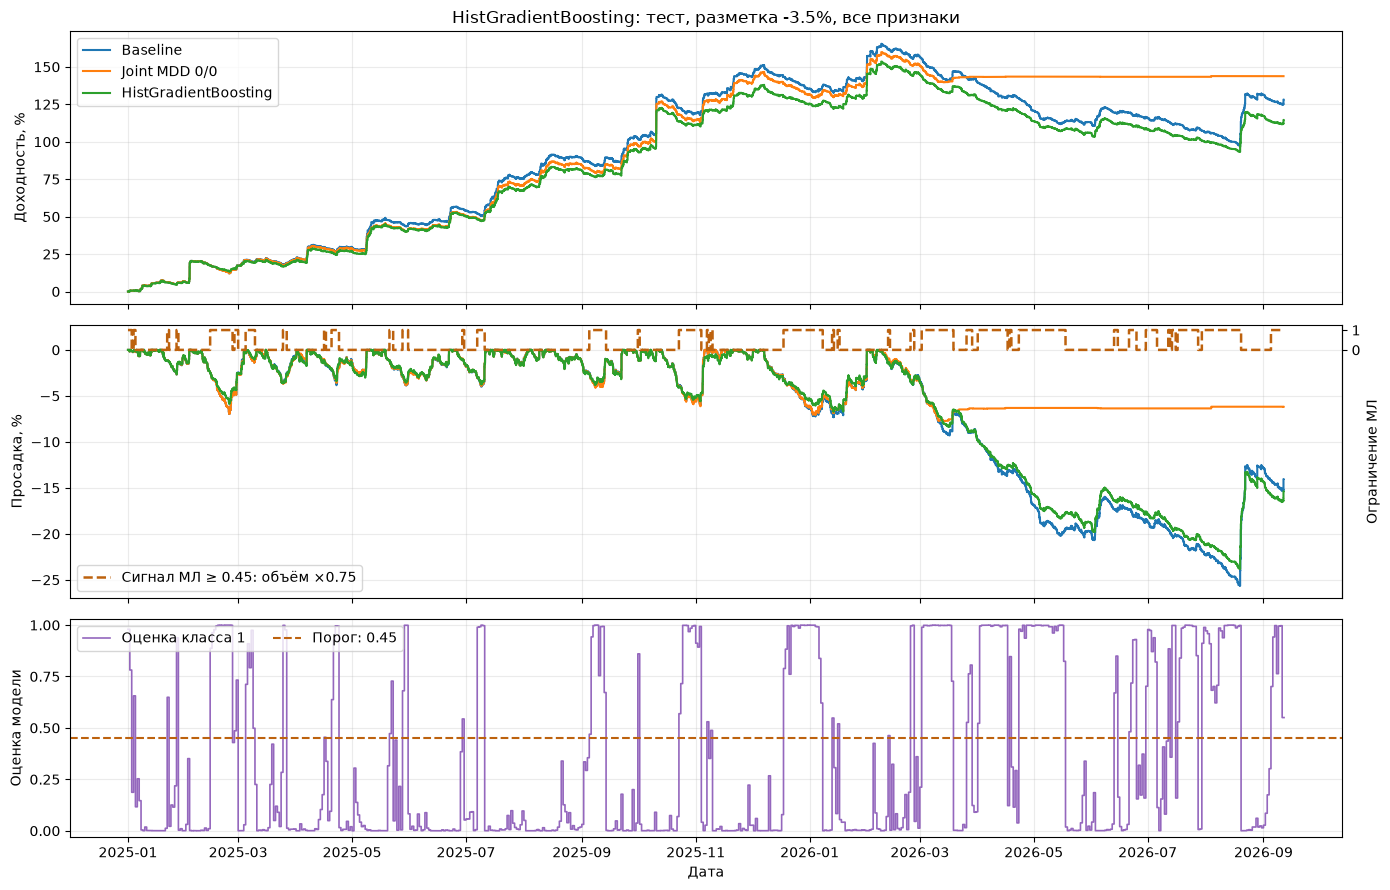

In [14]:
study_hist_boosting = run_study(
    labels_1, -3.5, classifier=HistGradientBoostingClassifier(random_state=42),
    method_name='HistGradientBoosting'
)

### Моделирование: AdaBoost (−3,5%)

ML: порог сигнала 0.70, объём ×0.


Threshold  Reduced_multiplier  Selected  Net_PnL_USDT  \
Method   Config_ID                                                          
Baseline 0                NaN                1.00     False    131068.914   
AdaBoost 24              0.70                0.00      True    131068.914   
         25              0.70                0.50     False    131068.914   
         26              0.70                0.75     False    131068.914   
         23              0.65                0.75     False    130653.467   
         22              0.65                0.50     False    130238.020   
         21              0.65                0.00     False    129407.127   
         20              0.60                0.75     False    127826.469   
         8               0.40                0.75     False    116188.130   
         7               0.40                0.50     False    101307.346   
         19              0.60                0.50     False    124584.023   
         17              0.55                0.75     False    125840.011   
         11              0.45                0.75     False    115451.349   
         16              0.55                0.50     False    120611.109   
         18              0.60                0.00     False    118099.133   
         14              0.50                0.75     False    122200.271   
         2               0.30                0.75     False     99351.008   
         5               0.35                0.75     False    102712.143   
         10              0.45                0.50     False     99833.785   
         13              0.50                0.50     False    113331.628   
         15              0.55                0.00     False    110153.303   
         1               0.30                0.50     False     67633.102   
         4               0.35                0.50     False     74355.371   
         6               0.40                0.00     False     71545.777   
         12              0.50                0.00     False     95594.342   
         9               0.45                0.00     False     68598.655   
         3               0.35                0.00     False     17641.829   
         0               0.30                0.00     False      4197.289   

                    PnL_delta_USDT  PnL_retained_pct  Return_pct  MDD_pct  \
Method   Config_ID                                                          
Baseline 0                   0.000           100.000     166.322    5.668   
AdaBoost 24                  0.000           100.000     166.322    5.668   
         25                  0.000           100.000     166.322    5.668   
         26                  0.000           100.000     166.322    5.668   
         23               -415.447            99.683     165.795    5.651   
         22               -830.894            99.366     165.268    5.633   
         21              -1661.787            98.732     164.213    5.598   
         20              -3242.445            97.526     162.208    5.589   
         8              -14880.784            88.647     147.439    5.096   
         7              -29761.569            77.293     128.556    4.467   
         19              -6484.891            95.052     158.093    5.509   
         17              -5228.903            96.011     159.687    5.579   
         11             -15617.565            88.084     146.504    5.273   
         16             -10457.805            92.021     153.052    5.569   
         18             -12969.781            90.105     149.864    5.454   
         14              -8868.643            93.234     155.068    5.686   
         2              -31717.906            75.801     126.073    4.710   
         5              -28356.771            78.365     130.338    4.979   
         10             -31235.130            76.169     126.686    4.842   
         13             -17737.286            86.467     143.814    5.704   
         15    

,Дней,Дней класса 1,Эпизодов класса 1,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC AUC,Average precision,Brier,TN,FP,FN,TP
Period,,,,,,,,,,,,,,,
Валидация 2024,356.0,44.0,2.0,0.876,0.5,0.0,0.0,0.0,0.768,0.449,0.167,312.0,0.0,44.0,0.0
Тест 2025,357.0,136.0,8.0,0.619,0.5,0.0,0.0,0.0,0.793,0.726,0.193,221.0,0.0,136.0,0.0
Тест 2026,231.0,205.0,2.0,0.113,0.5,0.0,0.0,0.0,0.829,0.975,0.222,26.0,0.0,205.0,0.0


Start_USDT    End_USDT  Net_PnL_USDT  PnL_retained_pct  \
Year Method                                                                  
2025 Baseline       209873.135  494037.906    284164.771            100.00   
     Joint MDD 0/0  209873.135  485939.882    276066.747             97.15   
     AdaBoost       209873.135  494037.906    284164.771            100.00   
2026 Baseline       494037.906  478801.108    -15236.798               NaN   
     Joint MDD 0/0  485939.882  511593.215     25653.333               NaN   
     AdaBoost       494037.906  478801.108    -15236.798               NaN   

                    PnL_delta_USDT  Return_pct  CAGR_pct  MDD_pct  DaR95_pct  \
Year Method                                                                    
2025 Baseline                0.000     135.398   135.536    6.967      4.801   
     Joint MDD 0/0       -8098.024     131.540   131.673    6.956      4.896   
     AdaBoost                0.000     135.398   135.536    6.967      4.801   
2026 Baseline                0.000      -3.084    -4.405   25.659     22.605   
     Joint MDD 0/0       40890.131       5.279     7.678    7.760      6.421   
     AdaBoost                0.000      -3.084    -4.405   25.659     22.605   

                    CDaR95_pct  Calmar  RecoveryFactor  Sharpe  Sortino  \
Year Method                                                               
2025 Baseline            5.498  19.455           8.382   3.797   15.929   
     Joint MDD 0/0       5.507  18.928           8.491   3.755   15.687   
     AdaBoost            5.498  19.455           8.382   3.797   15.929   
2026 Baseline           23.954  -0.172          -0.107  -0.198   -0.514   
     Joint MDD 0/0       7.180   0.989           0.606   0.924    2.446   
     AdaBoost           23.954  -0.172          -0.107  -0.198   -0.514   

                    Max_DD_duration_days  Time_underwater_pct  \
Year Method                                                     
2025 Baseline                       36.0               76.164   
     Joint MDD 0/0                  36.0               76.438   
     AdaBoost                       36.0               76.164   
2026 Baseline                      215.0               95.669   
     Joint MDD 0/0                 215.0               94.882   
     AdaBoost                      215.0               95.669   

                    Serious_DD_count  Serious_DD_days  Avg_multiplier  \
Year Method                                                             
2025 Baseline                    8.0             58.0           1.000   
     Joint MDD 0/0               8.0             57.0           0.982   
     AdaBoost                    8.0             58.0           1.000   
2026 Baseline                    1.0            198.0           1.000   
     Joint MDD 0/0               1.0            199.0           0.254   
     AdaBoost                    1.0            198.0           1.000   

                    Trades_half_pct  Trades_skipped_pct  Switches  \
Year Method                                                         
2025 Baseline                   0.0               0.000       0.0   
     Joint MDD 0/0              0.0               1.781      37.0   
     AdaBoost                   0.0               0.000       0.0   
2026 Baseline                   0.0               0.000       0.0   
     Joint MDD 0/0              0.0              74.630      98.0   
     AdaBoost                   0.0               0.000       0.0   

                    DaR95_pct_CI_low  DaR95_pct_CI_high  CDaR95_pct_CI_low  \
Year Method                                                                  
2025 Baseline                  3.390              5.344              4.040   
     Joint MDD 0/0             3.327              5.442              4.070   
     AdaBoost                  3.390              5.344              4.040   
2026 Baseline                 18.875             24.435             19.545   
     Joint MDD 0/0        

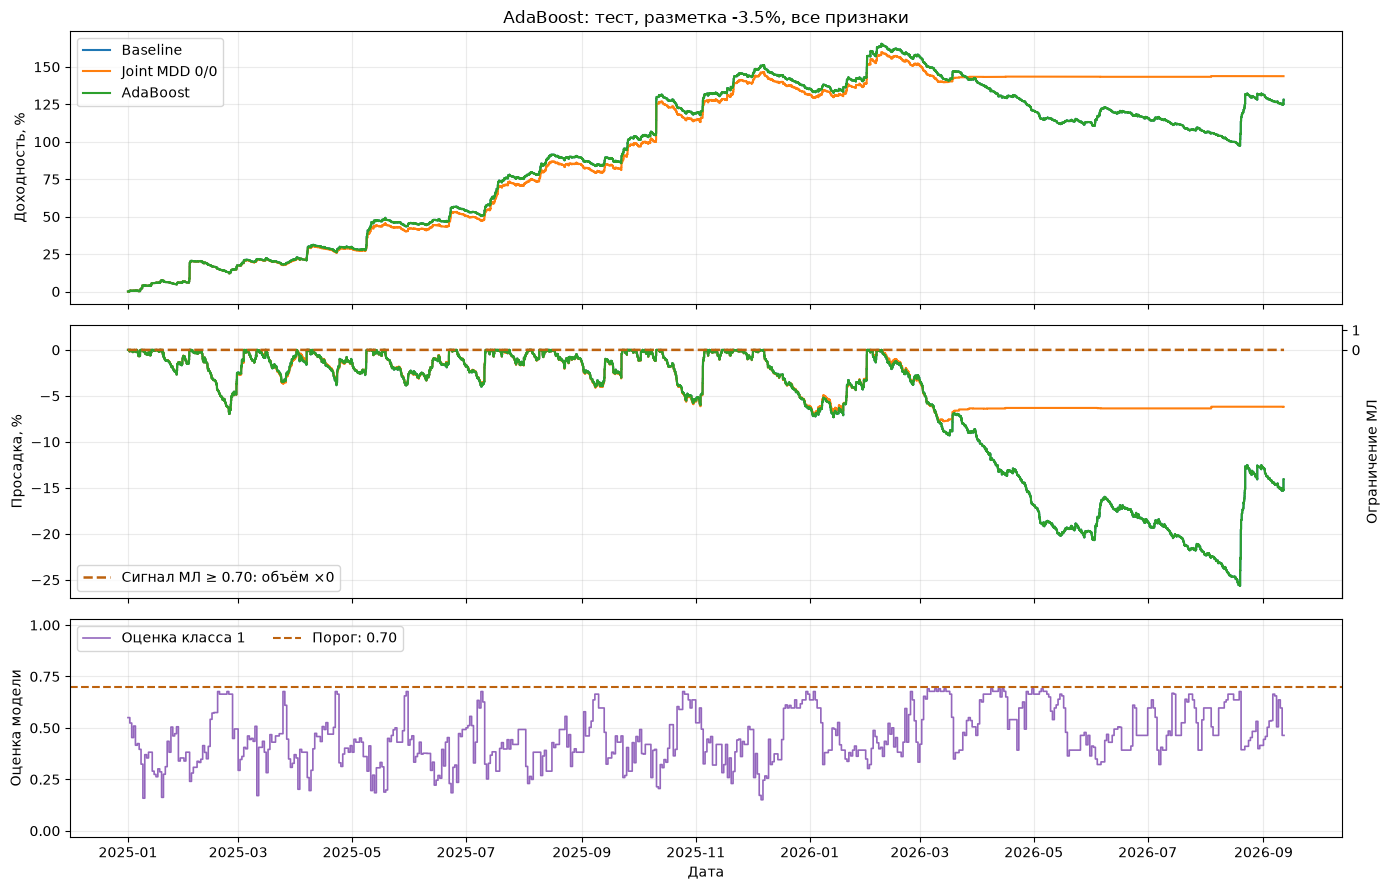

In [15]:
study_adaboost = run_study(
    labels_1, -3.5, classifier=AdaBoostClassifier(random_state=42),
    method_name='AdaBoost'
)

In [16]:
comparison_columns = ['Net_PnL_USDT', 'PnL_delta_USDT', 'MDD_pct', 'Calmar',
                      'Sharpe', 'Sortino', 'RecoveryFactor']
comparison = pd.concat({
    depth: run['summary'].xs(run['method_name'], level='Method')[comparison_columns].assign(
        **{'Порог сигнала': run['threshold'], 'Множитель': run['multiplier'],
                'Calmar валидации': run['validation_calmar']})
    for depth, run in [('−3,5%: все признаки', study_1), ('−2%: все признаки', study_2),
                       ('−5%: все признаки', study_3), ('−3,5%: только глубина', study_depth_only),
                       ('−3,5%: градиентный бустинг', study_boosting), ('−3,5%: CatBoost', study_catboost),
                       ('−3,5%: HistGradientBoosting', study_hist_boosting), ('−3,5%: AdaBoost', study_adaboost)]
}, names=['Модель', 'Year'])
benchmark_comparison = pd.concat({
    name: study_1['summary'].xs(name, level='Method')[comparison_columns].assign(
        **{'Порог сигнала': np.nan, 'Множитель': reduced, 'Calmar валидации': np.nan})
    for name, reduced in [('Baseline', 1.0), (reference_name, 0.0)]
}, names=['Модель', 'Year'])
ema_comparison = pd.concat({
    f'{run["method_name"]} + EMA ({run["ema_span"]} дн.)':
        run['summary'].xs(f'{run["method_name"]} + EMA', level='Method')[comparison_columns].assign(
            **{'Порог сигнала': run['threshold'], 'Множитель': run['multiplier'],
               'Calmar валидации': run['ema_validation_calmar']})
    for run in [study_1, study_catboost]
}, names=['Модель', 'Year'])
comparison = pd.concat([benchmark_comparison, comparison, ema_comparison])
display(comparison.round(3))

Net_PnL_USDT  PnL_delta_USDT  \
Модель                                 Year                                 
Baseline                               2025    284164.771           0.000   
                                       2026    -15236.798           0.000   
Joint MDD 0/0                          2025    276066.747       -8098.024   
                                       2026     25653.333       40890.131   
−3,5%: все признаки                    2025    239312.276      -44852.495   
                                       2026    -12687.856        2548.942   
−2%: все признаки                      2025    224594.244      -59570.527   
                                       2026     -8629.836        6606.963   
−5%: все признаки                      2025    241126.883      -43037.888   
                                       2026    -16613.560       -1376.762   
−3,5%: только глубина                  2025    235914.610      -48250.161   
                                       2026    -15307.034         -70.236   
−3,5%: градиентный бустинг             2025    254288.182      -29876.589   
                                       2026    -19789.153       -4552.355   
−3,5%: CatBoost                        2025    231395.376      -52769.395   
                                       2026    -20665.906       -5429.108   
−3,5%: HistGradientBoosting            2025    263045.825      -21118.946   
                                       2026    -22561.190       -7324.392   
−3,5%: AdaBoost                        2025    284164.771           0.000   
                                       2026    -15236.798           0.000   
Логистическая регрессия + EMA (14 дн.) 2025    235961.691      -48203.080   
                                       2026     -5793.853        9442.945   
CatBoost + EMA (14 дн.)                2025    217667.314      -66497.457   
                                       2026     -9178.033        6058.765   

                                             MDD_pct  Calmar  Sharpe  Sortino  \
Модель                                 Year                                     
Baseline                               2025    6.967  19.455   3.797   15.929   
                                       2026   25.659  -0.172  -0.198   -0.514   
Joint MDD 0/0                          2025    6.956  18.928   3.755   15.687   
                                       2026    7.760   0.989   0.924    2.446   
−3,5%: все признаки                    2025    4.555  25.056   3.475   15.583   
                                       2026   15.745  -0.256  -0.307   -0.829   
−2%: все признаки                      2025    4.310  24.855   3.640   15.961   
                                       2026   15.671  -0.181  -0.192   -0.531   
−5%: все признаки                      2025    4.525  25.413   3.472   15.395   
                                       2026   16.551  -0.317  -0.414   -1.089   
−3,5%: только глубина                  2025    5.047  22.295   3.404   14.016   
                                       2026   16.460  -0.298  -0.502   -1.178   
−3,5%: градиентный бустинг             2025    6.119  19.821   3.545   14.729   
                                       2026   23.697  -0.256  -0.353   -0.890   
−3,5%: CatBoost                        2025    5.073  21.754   3.363   14.327   
                                       2026   20.471  -0.326  -0.472   -1.189   
−3,5%: HistGradientBoosting            2025    5.853  21.436   3.669   15.588   
                                       2026   23.816  -0.285  -0.414   -1.039   
−3,5%: AdaBoost                        2025    6.967  19.455   3.797   15.929   
                                       2026   25.659  -0.172  -0.198   -0.514   
Логистическая регрессия + EMA (14 дн.) 2025    4.930  22.825   3.440   14.922   
                                       2026   15.840  -0.118  -0.127   -0.337   
CatBoost + EMA (14 дн.)                2025    5.891  17.623   3.210   13.156   
                 

# 4. SHAP

Используем готовый логрег способа 1 с разметкой −3,5%. Порог сигнала и множитель берём из подбора на 2024; модель обучена на 2021–2023. Модель, признаки и торговое правило здесь не меняем.

Вклады перекрывающихся окон суммируем по семействам: доходность, win rate и число закрытий. Глубина и длительность просадки показаны отдельно. Объясняем все даты теста 2025–2026, а в качестве опоры оставляем обучение 2021–2023. Слева — средний модуль группового вклада на тесте, справа — вклады на начало последней паузы. Вклады измерены в логарифме шансов класса `1`, не в процентах.

Для линейной модели используем [точную формулу interventional SHAP](https://shap.readthedocs.io/en/stable/generated/shap.LinearExplainer.html) с опорой на обучающие данные. Это объяснение оценки модели, а не причин просадки или эффекта на PnL.

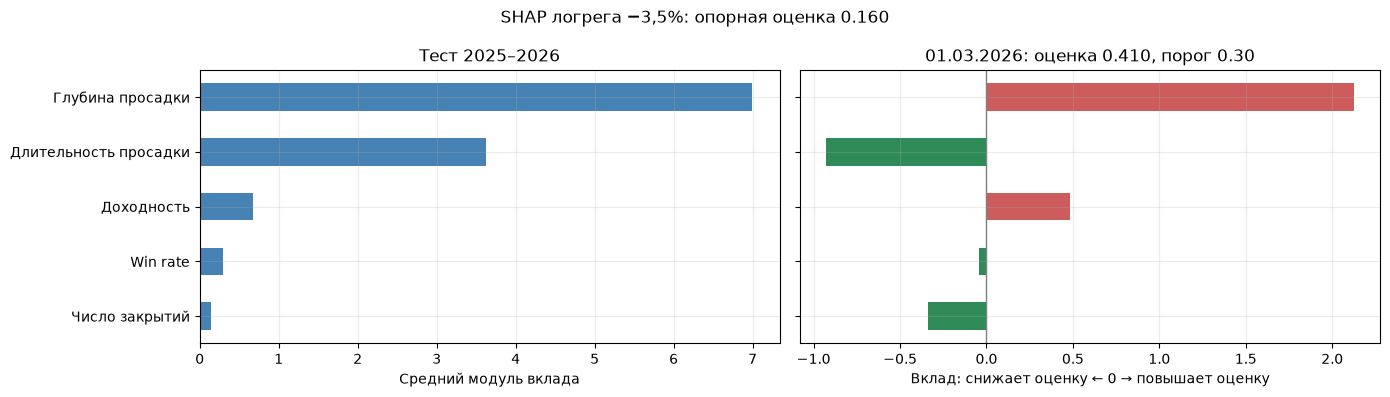

In [17]:
shap_model = study_1['model']
shap_threshold = study_1['threshold']
x_train_shap = features.loc[study_1['labels'][0].index]
x_test_shap = features.loc[test_days]
shap_transform = shap_model[:-1]
shap_logreg = shap_model[-1]

shap_reference = shap_transform.transform(x_train_shap).mean(axis=0)
shap_values = pd.DataFrame(
    (shap_transform.transform(x_test_shap) - shap_reference) * shap_logreg.coef_[0],
    index=x_test_shap.index, columns=x_test_shap.columns
)
shap_base = float(shap_logreg.intercept_[0] + shap_reference @ shap_logreg.coef_[0])
shap_groups = {
    'Глубина просадки': ['drawdown_pct'],
    'Длительность просадки': ['days_underwater'],
    'Доходность': [f'return_{days}d' for days in windows],
    'Win rate': [f'winrate_{days}d' for days in windows],
    'Число закрытий': [f'closes_{days}d' for days in windows],
}
shap_grouped = pd.DataFrame({
    name: shap_values[columns].sum(axis=1) for name, columns in shap_groups.items()
})
shap_importance = shap_grouped.abs().mean().sort_values()

shap_score = study_1['probability'].loc[shap_grouped.index]
shap_restricted = shap_score.ge(shap_threshold)
shap_starts = shap_restricted & ~shap_restricted.shift(fill_value=False)
shap_start_dates = shap_starts.index[shap_starts]
shap_example = shap_start_dates[-1] if len(shap_start_dates) else shap_score.idxmax()
shap_local = shap_grouped.loc[shap_example, shap_importance.index]
shap_reference_score = 1 / (1 + np.exp(-shap_base))

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
shap_importance.plot.barh(ax=axes[0], color='steelblue')
shap_local.plot.barh(ax=axes[1], color=np.where(shap_local.ge(0), 'indianred', 'seagreen'))
axes[0].set(title='Тест 2025–2026', xlabel='Средний модуль вклада')
axes[1].axvline(0, color='gray', linewidth=1)
axes[1].set(
    title=f'{shap_example:%d.%m.%Y}: оценка {shap_score.loc[shap_example]:.3f}, порог {shap_threshold:.2f}',
    xlabel='Вклад: снижает оценку ← 0 → повышает оценку'
)
fig.suptitle(f'SHAP логрега −3,5%: опорная оценка {shap_reference_score:.3f}')
plt.tight_layout()
plt.show()